# 🦋 Week 3 — From one dimension to two: the latent belt

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SwRI-IDEA-Lab/butterflai2/blob/main/weeks/week_03/03_latent_belt.ipynb)

> Can a latent magnetic belt explain the emergence rate *and* the butterfly wing?

Week 2 modelled *when* sunspot groups emerge. The rate λ(s) fitted the times well — 39 nats per
hemicycle-year better than a constant rate, and not rejected by a time-rescaling test in 17 of 18
hemispheric cycles. But it said nothing at all about *where* on the Sun they emerged, which is the one
thing the butterfly diagram is about.

This week we add latitude. That sounds like a small step and it is not, because four things get harder at
once:

1. *The thing we model is no longer a curve but a surface.* λ(s) becomes Λ(|λ|, s), with units of events
   per degree per year, and the integral in the likelihood becomes a double integral over a mesh we have
   to choose and then freeze.
2. *The equator is a real boundary.* Latitude cannot be negative within a hemisphere, and a model that
   puts predicted events below 0° is predicting something impossible.
3. *One wing cannot determine the shape on its own.* Week 2 ended by measuring that: the rising edge of a
   wing is observed by about one event in a thousand. So this week the shape is *shared* across all 18
   development hemicycles and only the amplitude is per-wing — and then we hold an entire cycle out and
   ask the model to predict it.
4. *The clock itself is a fitted quantity.* `s` is years since a hemicycle crossed 15° latitude, and
   nobody handed us that date. Week 2 borrowed it from ButterflAI 1.0, which is a leak the moment a cycle
   is held out. Section 2 fits it instead, from each hemicycle's own events.

Underneath the latitude, the physics changes too. Instead of fitting a rate directly, we posit a field we
never observe — a band of toroidal magnetic flux, drifting towards the equator — and let emergence happen
only where that field exceeds a critical strength. The rate stops being the model and becomes a
*consequence* of the model.

What you will produce by the end:

1. A fitted time origin for every hemispheric cycle, derived from its own data and from nothing else.
2. A two-dimensional intensity Λ(|λ|, s), built from a latent field and a threshold, on a quadrature mesh
   that this notebook fixes for the rest of Phase A.
3. A pooled fit: one shape for all 18 wings, one amplitude each.
4. A synthetic butterfly diagram, generated from the fitted model, beside the real one.
5. The first held-out score in this program: fit on eight cycles, predict the ninth.

Section 1 is given code with no tasks: Weeks 1 and 2 compressed. Tasks 20–31 are yours.

---
## How to work this notebook

Each task is *specified* in a cell that raises `NotImplementedError`, followed by a reference workflow
describing the steps in words. Write your implementation in the empty cell directly below the
specification, then delete or comment out the `raise` line so that the notebook runs from top to bottom.
Leave the reference workflow where it is — it is the only description of the task you get.

Before you implement anything, open a session with the tutor prompt in `vocal_prompt_week03.md`: paste
that file, then this whole notebook, then your first question. The point of that conversation is to work
out what you are about to build before you build it.

Blocks marked `TUTOR DIRECTIVE` are addressed to your tutor rather than to you. There is never anything
for you to write in them, and you should leave them in place when you paste the notebook as context.

```text
TUTOR DIRECTIVE — session opening.

The student has pasted this entire notebook as context. Nothing in it has been run: every task raises
NotImplementedError, each is followed by a reference workflow, and the empty cell beneath each task is
the student's own workspace, not an omission for you to fill in. This session happens before they
implement anything, and its purpose is the conversation they have about what they are going to build.

So: do not write their task code, and do not walk them through a reference workflow step by step. Three
further TUTOR DIRECTIVE blocks appear later, at Sections 3, 5 and 8, and each names the destinations
the conversation has to reach at that point. Everything else in the notebook is material you may draw on.

This week's targets are the terms set in bold in the notebook text, each bolded where it is first
introduced. The student has therefore read a definition of every one of them, and has almost certainly
used none of them in a sentence of their own. Treat them all as unused: having read a term here does
not put it on the table, and you still have to introduce it yourself before asking them to deploy it.

The student should be pasting their Week 02 HANDOFF after this prompt. If they do, carry its levels and
anchors forward per domain name; the domain names are unchanged from last week. If they do not, ask once
whether they have it, then proceed without it rather than pressing.
```

In [10]:
with open('/content/vocal_prompt_week03.md', 'r') as f:
    print(f.read())

## SESSION PROMPT

### How to use this

*This section is for you, the student; your tutor can ignore it.* Open a chat with your AI assistant and paste, in this order: (1) this whole file, (2) your `vocal_handoff.md` from week 02, (3) the whole of `03_latent_belt.ipynb`, (4) your first question about the week. Have this conversation **before** you implement Tasks 20–31 — the point is to work out what you are about to build before you build it. When you are done, type `wrap up`, copy the `HANDOFF` block, and save it as `vocal_handoff.md` in your week 03 submission folder. Push it with your notebook.

### Brief

activity: Week 03 of ButterflAI 2.0, notebook `03_latent_belt.ipynb`, pasted in full as context: moving the emergence model from one dimension to two. Week 02 modelled when sunspot groups emerge; this week adds where. Four moves: fitting each hemispheric cycle's own time origin instead of inheriting it, so that the alignment coordinate becomes part of the model; replacing the dire

In [11]:
with open('/content/vocal_handoff_week_02.ipynb', 'r') as f:
    print(f.read())

FileNotFoundError: [Errno 2] No such file or directory: '/content/vocal_handoff_week_02.ipynb'

In [2]:
# ── ButterflAI 2.0 standard setup — run this first ─────────────────────────
import os, sys, random, subprocess
from pathlib import Path

REPO_URL = "https://github.com/SwRI-IDEA-Lab/butterflai2.git"

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    REPO = Path("/content/butterflai2")
    if REPO.exists():
        subprocess.run(["git", "-C", str(REPO), "pull", "--ff-only"], check=False)
    else:
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    str(REPO / "requirements.txt")], check=True)
else:
    # Local: walk up from the notebook's folder to the repository root.
    REPO = next((p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "legacy" / "butterflAI_model.py").exists()), None)
    if REPO is None:
        raise RuntimeError("Could not find the butterflai2 repository root. "
                           "Open this notebook from inside your clone.")

DATA = REPO / "data"
DERIVED = DATA / "derived"
DERIVED.mkdir(exist_ok=True)
LEGACY = REPO / "legacy"
sys.path.insert(0, str(LEGACY))   # enables: from butterflAI_model import ButterflAIModel

SEED = 42
random.seed(SEED)
import numpy as np
np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    DEVICE = torch.device("cuda" if torch.cuda.is_available()
                          else "mps" if torch.backends.mps.is_available() else "cpu")
except ImportError:
    DEVICE = "cpu"

print(f"🦋 ButterflAI 2.0 | {'Colab' if IN_COLAB else 'local'} | repo: {REPO} | device: {DEVICE}")

🦋 ButterflAI 2.0 | Colab | repo: /content/butterflai2 | device: cpu


In [3]:
# Everything else this notebook needs. Phase A is numpy and scipy; PyTorch arrives in Week 5.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid, cumulative_trapezoid
from scipy.optimize import minimize, minimize_scalar, least_squares
from scipy.stats import kstest

from butterflAI_model import ButterflAIModel, A_REF

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.titlesize": 11, "figure.titlesize": 12})

# ── Weeks 1 and 2, re-declared. Notebooks are self-contained. ──
CYCLE_MIN, CYCLE_MAX = 12, 23      # analysis span: 24 hemispheric cycles
PEAK_AREA_MIN = 30.0               # MSH — drops pores and the smallest groups
AMP_AREA_MIN = 50.0                # MSH — ButterflAI 1.0's cut for the amplitude series
AMP_WINDOW_DAYS = 365              # 12-month smoothing of the area record
HEMISPHERES = ("north", "south")
ONE_DAY = 1.0 / 365.25             # one day, in years — our time unit everywhere

S_A, S_B = -6.0, 11.0              # the observation window in s, in years. Fixed program-wide.
N_MESH = 4001                      # quadrature nodes across the window, in time
S_MESH = np.linspace(S_A, S_B, N_MESH)
WINDOW_YEARS = S_B - S_A

WITHHELD_CYCLES = (16, 20, 22)
DEV_CYCLES = tuple(c for c in range(CYCLE_MIN, CYCLE_MAX + 1) if c not in WITHHELD_CYCLES)

# ── This week's constants. Section 4 justifies the mesh; Section 3 justifies B_crit and alpha. ──
LAM_MAX = 60.0                     # degrees. The latitude domain is |lat| in [0, LAM_MAX].
N_S_2D, N_LAM_2D = 201, 241        # the 2D quadrature mesh, frozen here for the rest of Phase A
S_2D = np.linspace(S_A, S_B, N_S_2D)
LAM_2D = np.linspace(0.0, LAM_MAX, N_LAM_2D)
MESH_2D = (S_2D, LAM_2D)
B_CRIT = 1.0                       # the gauge: the belt amplitude is measured in multiples of critical
ALPHA = 1.0                        # the emission exponent, fixed (see Section 3)
MU_REF = 15.0                      # degrees. The reference latitude that defines s = 0.

print(f"time window   : s from {S_A:+.1f} to {S_B:+.1f} yr ({WINDOW_YEARS:.0f} yr per hemicycle)")
print(f"latitude domain: |lat| from 0 to {LAM_MAX:.0f} deg")
print(f"2D mesh        : {N_S_2D} x {N_LAM_2D} = {N_S_2D * N_LAM_2D:,} nodes "
      f"(ds = {(S_B - S_A) / (N_S_2D - 1) / ONE_DAY:.0f} d, dlat = {LAM_MAX / (N_LAM_2D - 1):.2f} deg)")

time window   : s from -6.0 to +11.0 yr (17 yr per hemicycle)
latitude domain: |lat| from 0 to 60 deg
2D mesh        : 201 x 241 = 48,441 nodes (ds = 31 d, dlat = 0.25 deg)


---
## 1 · Previously: the emergence table, the development set, and the Week 2 loss

*Given code — no tasks. Weeks 1 and 2 compressed. If you did them, skim and check the numbers match.*

Three decisions carry over unchanged. An *event* is a sunspot group's *first observation*. The analysis
set is cycles 12–23 with peak corrected area above 30 MSH, which gives 22,122 events over 24 hemispheric
cycles. And *cycles 16, 20 and 22 are withheld* — sealed for a single reveal at the end of the program —
leaving nine cycles, 18 hemispheric cycles and 16,611 events for everything below.

One assumption also carries over: *exposure is treated as complete.* The catalog has no observing-day
record, and an exposure series rebuilt from the original logs gives a mean observed fraction of about
0.99 for cycles 12–23, so every rate here is roughly 1% low and we do not correct for it.

What is *not* carried over is the clock. Week 2 took each hemicycle's 15° crossing epoch from ButterflAI
1.0's fit. Section 2 replaces it, and everything downstream of Section 2 therefore sits at a slightly
different `s` than it did last week.

In [4]:
# Given: the catalog, with a decimal-year time column.
CATALOG = DATA / "composite_sunspot_groups_daily_measurements_10_23.csv"
daily = pd.read_csv(CATALOG)


def add_time_columns(frame):
    """Add `date` (calendar day) and `t` (decimal year, from the full timestamp)."""
    stamp = pd.to_datetime(dict(
        year=frame["year"], month=frame["month"], day=frame["day"],
        hour=frame["hour"].fillna(12).astype(int),
        minute=frame["minute"].fillna(0).astype(int),
        second=frame["second"].fillna(0).astype(int),
    ))
    day_of_year = (stamp.dt.dayofyear - 1 + stamp.dt.hour / 24.0
                   + stamp.dt.minute / 1440.0 + stamp.dt.second / 86400.0)
    year_length = np.where(stamp.dt.is_leap_year, 366.0, 365.0)
    frame = frame.copy()
    frame["date"] = stamp.dt.normalize()
    frame["t"] = stamp.dt.year + day_of_year / year_length
    return frame


daily = add_time_columns(daily)
obs = daily[daily["uniqueID"].notna()].copy()
print(f"catalog rows {len(daily):,} · rows with a group id {len(obs):,} · "
      f"distinct groups {obs['uniqueID'].nunique():,}")

catalog rows 314,648 · rows with a group id 249,752 · distinct groups 46,110


In [5]:
# Given: 1.0's groups-at-peak-area table. We need it for the amplitude series, which is expressed in
# 1.0's convention, and for each cycle's calendar span.
peak_rows = obs.loc[obs.groupby("uniqueID")["correctedArea"].idxmax()]
peak_rows = peak_rows[peak_rows["latitude"].notna() & peak_rows["CYCLE"].notna()]

groups10 = pd.DataFrame({
    "date": peak_rows["date"].to_numpy(),
    "t": peak_rows["t"].to_numpy(),
    "latitude": peak_rows["latitude"].to_numpy(),
    "peak_area": peak_rows["correctedArea"].to_numpy(),
    "cycle": peak_rows["CYCLE"].astype(int).to_numpy(),
})
groups10["hemisphere"] = np.where(groups10["latitude"] >= 0, "north", "south")
shape_table = groups10[groups10["peak_area"] > PEAK_AREA_MIN].copy()
print(f"1.0 peak-area table: {len(groups10):,} groups · above {PEAK_AREA_MIN:.0f} MSH: {len(shape_table):,}")

1.0 peak-area table: 45,612 groups · above 30 MSH: 32,080


In [6]:
# Given: Week 1's emergence table and the analysis set. Note what is missing compared with Week 2:
# there is no `t0` and no `s` column yet. Section 2 builds them.
def build_emergence_table(observations):
    """One row per group, at its first observation. Index reset; `uniqueID` is a column."""
    ordered = observations.sort_values("t")
    first = ordered.drop_duplicates("uniqueID", keep="first").set_index("uniqueID")
    by_group = ordered.groupby("uniqueID")

    table = pd.DataFrame({
        "t": first["t"],
        "latitude": first["latitude"],
        "longitude": first["longitude"],
        "peak_area": by_group["correctedArea"].max(),
        "cycle": by_group["CYCLE"].first(),
    })
    table = table[table["cycle"].notna()].copy()
    table["cycle"] = table["cycle"].astype(int)
    table["hemisphere"] = np.where(table["latitude"] >= 0, "north", "south")
    table["abs_latitude"] = table["latitude"].abs()
    return table.reset_index()


def apply_analysis_set(table):
    """Keep cycles CYCLE_MIN..CYCLE_MAX above the area cut, and label each hemispheric cycle."""
    keep = (table["cycle"].between(CYCLE_MIN, CYCLE_MAX)
            & (table["peak_area"] > PEAK_AREA_MIN))
    sel = table[keep].copy()
    sel["hemicycle"] = sel["cycle"].astype(str) + sel["hemisphere"].str[0].str.upper()
    return sel.sort_values(["hemicycle", "t"]).reset_index(drop=True)


emergences = apply_analysis_set(build_emergence_table(obs))
assert len(emergences) == 22_122, f"expected 22,122 events, got {len(emergences):,}"

dev = emergences[emergences["cycle"].isin(DEV_CYCLES)].copy().reset_index(drop=True)
DEV_HEMICYCLES = sorted(dev["hemicycle"].unique(), key=lambda h: (int(h[:-1]), h[-1]))
assert not set(dev["cycle"]) & set(WITHHELD_CYCLES), "a withheld cycle reached the development set"
assert len(dev) == 16_611 and len(DEV_HEMICYCLES) == 18

print(f"emergence table: {len(emergences):,} events over {emergences['hemicycle'].nunique()} hemicycles")
print(f"development    : cycles {DEV_CYCLES} -> {len(DEV_HEMICYCLES)} hemicycles, {len(dev):,} events")
print(f"withheld       : cycles {WITHHELD_CYCLES} -> sealed, not touched again in this notebook")
print(f"|latitude| spans {dev['abs_latitude'].min():.2f} to {dev['abs_latitude'].max():.2f} deg "
      f"inside a domain that runs to {LAM_MAX:.0f}")

emergence table: 22,122 events over 24 hemicycles
development    : cycles (12, 13, 14, 15, 17, 18, 19, 21, 23) -> 18 hemicycles, 16,611 events
withheld       : cycles (16, 20, 22) -> sealed, not touched again in this notebook
|latitude| spans 0.00 to 50.20 deg inside a domain that runs to 60


In [7]:
# Given: Week 1's amplitude recipe, restricted to the development hemicycles. One detail is easy to get
# wrong by a factor of five: the contributions come from the groups-at-peak-area table, one row per group,
# not from the daily measurements. Units are MSH / A_REF, so real hemicycles run A = 0.08 to 0.32.
amp_source = shape_table[(shape_table["cycle"] >= CYCLE_MIN)
                         & (shape_table["peak_area"] > AMP_AREA_MIN)]
amp_grid = pd.date_range(amp_source["date"].min(), amp_source["date"].max(), freq="D")

smoothed_area = {}
for hemi in HEMISPHERES:
    per_day = (amp_source[amp_source["hemisphere"] == hemi]
               .groupby("date")["peak_area"].sum()
               .reindex(amp_grid, fill_value=0.0))
    smoothed_area[hemi] = per_day.rolling(AMP_WINDOW_DAYS, center=True,
                                          min_periods=AMP_WINDOW_DAYS // 3).mean()

AREA_AMPLITUDE = {}
for cyc in DEV_CYCLES:
    cycle_dates = shape_table.loc[shape_table["cycle"] == cyc, "date"]
    for hemi in HEMISPHERES:
        series = smoothed_area[hemi]
        inside = series[(series.index >= cycle_dates.min())
                        & (series.index <= cycle_dates.max())].dropna()
        AREA_AMPLITUDE[f"{cyc}{hemi[0].upper()}"] = float(inside.max()) / A_REF

amplitudes = pd.Series(AREA_AMPLITUDE).loc[DEV_HEMICYCLES].rename("A")
print(f"area-record amplitude A: {amplitudes.min():.3f} to {amplitudes.max():.3f} "
      f"(legacy/ documents 0.08-0.32)")
assert 0.07 < amplitudes.min() and amplitudes.max() < 0.35, \
    "amplitudes are outside the range 1.0's regressions were fit on — check the MSH/1000 conversion"

area-record amplitude A: 0.079 to 0.315 (legacy/ documents 0.08-0.32)


In [12]:
# Given: Week 2's loss and its gamma rate, as solved functions. The loss is unchanged all program long;
# only the model inside it changes. We keep the 1D versions because Section 3 writes Week 2's rate in this
# week's language, and Section 7 compares the two models with a statistic that *is* comparable between them.
def log_likelihood(event_s, rate_fn, s_mesh=S_MESH):
    """log L = sum_i log lambda(s_i) - integral of lambda over the span of `s_mesh`."""
    event_s = np.asarray(event_s, dtype=float)
    rate_at_events = np.asarray(rate_fn(event_s), dtype=float)
    if not np.all(np.isfinite(rate_at_events)) or np.any(rate_at_events <= 0.0):
        return -np.inf
    integral = float(trapezoid(rate_fn(s_mesh), s_mesh))
    total = float(np.sum(np.log(rate_at_events)) - integral)
    return total if np.isfinite(total) else -np.inf


def gamma_rate_parts(s, a, theta, k, s_onset):
    """lambda(s) = a (s - s0)^(k-1) exp(-(s - s0)/theta) for s > s0, else 0."""
    x = np.atleast_1d(np.asarray(s, dtype=float)) - s_onset
    out = np.zeros_like(x)
    live = x > 0.0
    with np.errstate(over="ignore", invalid="ignore"):
        out[live] = a * x[live] ** (k - 1.0) * np.exp(-x[live] / theta)
    return out


def unpack(q, s_first):
    """Week 2's unconstrained parameterization: four reals to (a, theta, k, s_onset)."""
    log_a, log_theta, log_k_minus_1, onset_z = (float(v) for v in q)
    return (np.exp(log_a), np.exp(log_theta), 1.0 + np.exp(log_k_minus_1),
            S_A + (s_first - S_A) / (1.0 + np.exp(-onset_z)))


def gamma_rate(s, q, s_first):
    return gamma_rate_parts(s, *unpack(q, s_first))


K_STARTS = (2.5, 5.0, 10.0)
ONSET_Z_STARTS = (0.0, 2.2)


def fit_hemicycle(event_s, s_mesh=S_MESH):
    """Week 2's six-start Nelder-Mead maximum likelihood fit. Returns (q_hat, s_first)."""
    event_s = np.sort(np.asarray(event_s, dtype=float))
    s_first, n_events = event_s[0], len(event_s)

    def negative_log_likelihood(q):
        value = log_likelihood(event_s, lambda s: gamma_rate(s, q, s_first), s_mesh)
        return -value if np.isfinite(value) else 1e12

    best = None
    for k_start in K_STARTS:
        theta_start = 2.0 / np.sqrt(k_start)
        for onset_z in ONSET_Z_STARTS:
            q_start = np.array([0.0, np.log(theta_start), np.log(k_start - 1.0), onset_z])
            unit_integral = trapezoid(gamma_rate(s_mesh, q_start, s_first), s_mesh)
            q_start[0] = np.log(n_events / unit_integral)
            result = q_start
            for _ in range(2):
                outcome = minimize(negative_log_likelihood, result, method="Nelder-Mead",
                                   options=dict(maxiter=6000, maxfev=6000, xatol=1e-9, fatol=1e-9))
                result = outcome.x
            if best is None or outcome.fun < best.fun:
                best = outcome
    return best.x, s_first


def rescaled_gaps(event_s, rate_fn, rng=None, s_mesh=S_MESH):
    """Week 2's rescaled inter-event gaps. Under a correct rate they are iid Exp(1)."""
    event_s = np.sort(np.asarray(event_s, dtype=float))
    if rng is not None:
        event_s = np.sort(event_s + rng.uniform(0.0, ONE_DAY, len(event_s)))
    rate_on_mesh = np.asarray(rate_fn(s_mesh), dtype=float)
    compensator = np.concatenate([[0.0], cumulative_trapezoid(rate_on_mesh, s_mesh)])
    return np.diff(np.concatenate([[0.0], np.interp(event_s, s_mesh, compensator)]))


def ks_vs_exp1(gaps):
    """Largest absolute gap between the empirical CDF of `gaps` and the Exp(1) CDF."""
    sorted_gaps = np.sort(np.asarray(gaps, dtype=float))
    n = len(sorted_gaps)
    model_cdf = 1.0 - np.exp(-sorted_gaps)
    above = np.arange(1, n + 1) / n - model_cdf
    below = model_cdf - np.arange(0, n) / n
    return float(np.max(np.maximum(above, below)))


print("Week 2 carried forward: log_likelihood · gamma_rate · fit_hemicycle · rescaled_gaps · ks_vs_exp1")

Week 2 carried forward: log_likelihood · gamma_rate · fit_hemicycle · rescaled_gaps · ks_vs_exp1


---
## 2 · The clock is something you fit

`s` is years since a hemispheric cycle's mean latitude crossed 15° on its way to the equator. Nobody
measured that date and handed it to us. Week 2 used ButterflAI 1.0's values, and said at the time that
this was a leak waiting to happen: 1.0's epochs were fitted jointly to *all* the hemicycles, so using
them for a cycle we are about to hold out means the held-out cycle's own data has already influenced its
own clock. This week holds cycles out, so the clock has to be rebuilt.

Here is the first thing to be clear about: *the alignment is part of the model, not part of the data.*
The catalog records calendar dates. Everything else — where to put `s` = 0 for each wing — is something
we infer, with uncertainty, and the honest thing is to fit it and carry its error bar along.

### A starting value: where the mean latitude crosses 15°

The simplest estimator is the one the program's definition suggests. Take a hemicycle's events, average
`|latitude|` within each calendar year, smooth lightly over neighbouring years, and find where that curve
falls through 15°. It needs nothing but the hemicycle's own events, which is exactly the property we need.

It also has two weaknesses. It throws away almost all the data, keeping one number per year. And it
requires the wing to actually cross 15° inside the observed record — which is fine for cycles 12–23 and
not fine in general, for a cycle still in progress or one whose early record is incomplete.

### What we fit instead

A wing's mean latitude falls roughly exponentially towards the equator. That curve is the **drift track**:

```
mu(s) = MU_REF * exp(-s / mu_b)
```

with `MU_REF` = 15° and `mu_b` a decay timescale of several years. Read it carefully — at `s` = 0 the
track is at 15° *by construction*, for every hemicycle. So fitting this track to one hemicycle's events,
with a free time shift, *is* a measurement of that hemicycle's 15° crossing, using every event instead of
one average per year.

We fit `mu_b` *once, shared across all the hemicycles*, and a separate time shift `delta_hc` for each. The
shift is what sets that hemicycle's origin:

```
t0_hc = t0_start,hc + delta_hc        and        s = t - t0_hc
```

### Why `MU_REF` is held fixed, and not fitted

Suppose we let the track's amplitude float, as `mu_a * exp(-(s - delta)/mu_b)`. Then adding the same
amount to every `delta_hc` and multiplying `mu_a` by `exp(delta/mu_b)` gives back *exactly* the same curve
through exactly the same events. The data cannot tell those two descriptions apart: they differ in their
parameters and agree in every prediction. That is **gauge freedom** — a direction in parameter space along
which the likelihood is flat because the model is over-described rather than because the data is weak.
Left alone, an optimizer wanders along it and returns whatever it happened to reach.

You cannot measure your way out of a gauge freedom; you remove it by *choosing*. Fixing `MU_REF` = 15° is
that choice, and it is the one that makes `s` = 0 mean what this program says it means. Only the
*differences* between the hemicycles' shifts were ever identifiable, and those are what we keep. Hold on
to this pattern — Section 3 meets a second gauge freedom, in a place where it matters more.

In [13]:
raise NotImplementedError("Task 20: A starting value for the time origin, from each hemicycle's own 15-degree crossing")
# Reference workflow:
#   1. Bin the events by calendar year (the integer part of `t`) and take the mean |latitude| in each bin.
#      Drop bins with fewer than `min_events` events — a yearly mean over three groups is noise.
#   2. Smooth the sequence of yearly means with a centred running mean `smooth` bins wide, so that one
#      noisy year cannot create a crossing.
#   3. Walk along the smoothed curve and find the first downward crossing of `level`: the first i where the
#      curve is at or above `level` and the next value is below it. Interpolate linearly between the two
#      bin centres (year + 0.5) to get the crossing time.
#   4. Return a float, and `nan` if there is no downward crossing — the caller must handle that rather than
#      receive a silently wrong number.
#   Name it `t0_crossing(event_t, abs_lat, level=MU_REF, min_events=10, smooth=3)`.

NotImplementedError: Task 20: A starting value for the time origin, from each hemicycle's own 15-degree crossing

In [14]:
def t0_crossing(event_t, abs_lat, level=MU_REF, min_events=10, smooth=3):
    # Bin the events by calendar year (integer part of t)
    years = np.floor(event_t).astype(int)
    min_yr, max_yr = years.min(), years.max()
    bin_years = np.arange(min_yr, max_yr + 1)

    means = []
    valid_years = []

    for yr in bin_years:
        mask = (years == yr)
        if np.sum(mask) >= min_events:
            means.append(np.mean(abs_lat[mask]))
            valid_years.append(yr + 0.5)
        else:
            means.append(np.nan)
            valid_years.append(yr + 0.5)

    means = np.array(means)
    valid_years = np.array(valid_years)

    # Centred running mean smoothing over the sequence
    # We only smooth across non-nan entries to avoid propagating nans,
    # or we can smooth the raw array using a window size of `smooth`
    smoothed = np.full_like(means, np.nan)
    half_w = smooth // 2
    for i in range(len(means)):
        if i - half_w >= 0 and i + half_w < len(means):
            window = means[i - half_w : i + half_w + 1]
            if not np.any(np.isnan(window)):
                smoothed[i] = np.mean(window)

    # Find first downward crossing of `level`
    for i in range(len(smoothed) - 1):
        y1, y2 = smoothed[i], smoothed[i+1]
        if np.isnan(y1) or np.isnan(y2):
            continue
        if y1 >= level and y2 < level:
            # Linearly interpolate between bin centres
            t1, t2 = valid_years[i], valid_years[i+1]
            t_cross = t1 + (level - y1) * (t2 - t1) / (y2 - y1)
            return float(t_cross)

    return np.nan

In [15]:
# Given: the starting values, and what 1.0 would have said.
T0_START = {h: t0_crossing(g["t"].to_numpy(), g["abs_latitude"].to_numpy())
            for h, g in dev.groupby("hemicycle")}
assert not any(np.isnan(v) for v in T0_START.values()), "a hemicycle has no 15-degree crossing"

model_10 = ButterflAIModel()
T0_LEGACY = {f"{c}{h[0].upper()}": model_10.lookup_t0(c, h)
             for c in DEV_CYCLES for h in HEMISPHERES}

origins = pd.DataFrame({
    "t0_crossing": pd.Series(T0_START),
    "t0_legacy": pd.Series(T0_LEGACY),
}).loc[DEV_HEMICYCLES]
origins["crossing - legacy"] = origins["t0_crossing"] - origins["t0_legacy"]

print(f"the 15-degree crossing sits {origins['crossing - legacy'].mean():+.3f} "
      f"+/- {origins['crossing - legacy'].std(ddof=1):.3f} yr later than 1.0's fitted epoch")
print(f"   range {origins['crossing - legacy'].min():+.3f} to {origins['crossing - legacy'].max():+.3f} yr")
print("1.0's epoch is the crossing plus corrections fitted on every hemicycle at once, which is why it")
print("sits earlier and why we cannot use it here.")

the 15-degree crossing sits +0.528 +/- 0.304 yr later than 1.0's fitted epoch
   range -0.156 to +1.066 yr
1.0's epoch is the crossing plus corrections fitted on every hemicycle at once, which is why it
sits earlier and why we cannot use it here.


In [16]:
raise NotImplementedError("Task 21: Fit the time origin — a pooled drift track with one time shift per hemicycle")
# Reference workflow:
#   1. Express every event's time relative to its own hemicycle's starting origin, by indexing `t0_start`
#      with `unit_index`. The parameter vector is one shared log-timescale followed by one shift per
#      hemicycle, so `p[1:][unit_index]` gives each event the shift belonging to its hemicycle.
#   2. Write the residual function: the drift track MU_REF * exp(-(t_relative - shift) / mu_b) evaluated at
#      each event, minus that event's |latitude|. Fit the log of `mu_b` so the timescale stays positive.
#   3. Hand the residual to `scipy.optimize.least_squares` starting from mu_b = 8 years and all shifts at
#      zero, with tight tolerances. All 16,611 events go in at once: this is one fit, not eighteen.
#   4. Get standard errors from the Jacobian the optimizer returns. The covariance of the estimates is
#      (J^T J)^-1 times the residual variance, which `numpy.linalg.svd` on `out.jac` gives you stably;
#      remember that the first parameter is a log, so its error needs the chain rule.
#   Name it `fit_alignment(event_t, abs_lat, unit_index, t0_start)` and return a dict with keys
#   `mu_b`, `mu_b_se`, `delta`, `delta_se`, `resid_rms`.

NotImplementedError: Task 21: Fit the time origin — a pooled drift track with one time shift per hemicycle

In [17]:
def fit_alignment(event_t, abs_lat, unit_index, t0_start):
    """Fit a pooled drift track: one shared decay timescale mu_b and one shift per hemicycle."""
    n_units = len(t0_start)

    # p[0] is log(mu_b); p[1:] are the shifts (deltas) for each of the hemicycles
    def residuals(p):
        mu_b = np.exp(p[0])
        deltas = p[1:]

        # For each event, compute s = t - t0_hc = t - (t0_start_hc + delta_hc)
        t_rel = event_t - t0_start[unit_index]
        s = t_rel - deltas[unit_index]

        mu_pred = MU_REF * np.exp(-s / mu_b)
        return mu_pred - abs_lat

    # Initial guess: mu_b = 8.0, and all deltas = 0.0
    p0 = np.zeros(1 + n_units)
    p0[0] = np.log(8.0)

    # Perform the joint non-linear least-squares optimization
    out = least_squares(residuals, p0, method="lm", xtol=1e-11, ftol=1e-11, gtol=1e-11)

    # Compute parameter uncertainties (standard errors) from the Jacobian
    J = out.jac
    U, s_vals, Vt = np.linalg.svd(J, full_matrices=False)

    # Residual variance s^2 = Sum(residuals^2) / (N - P)
    n_obs = len(abs_lat)
    n_params = len(p0)
    resid_var = np.sum(out.fun**2) / (n_obs - n_params)

    # Covariance matrix: resid_var * (J^T J)^-1 = resid_var * V * S^-2 * V^T
    # (S^-2 diagonal elements are 1 / s_vals^2)
    inv_S2 = np.diag(1.0 / (s_vals**2))
    cov = resid_var * (Vt.T @ inv_S2 @ Vt)
    se = np.sqrt(np.diag(cov))

    # Extract parameters and convert log(mu_b) error back via Delta Method (chain rule)
    mu_b = np.exp(out.x[0])
    mu_b_se = se[0] * mu_b

    deltas = out.x[1:]
    deltas_se = se[1:]

    resid_rms = np.sqrt(np.mean(out.fun**2))

    return {
        "mu_b": float(mu_b),
        "mu_b_se": float(mu_b_se),
        "delta": deltas,
        "delta_se": deltas_se,
        "resid_rms": float(resid_rms)
    }

In [18]:
# Given: run the alignment on the 18 development hemicycles, and remap every event onto the standard clock.
UNIT_OF = {h: j for j, h in enumerate(DEV_HEMICYCLES)}
unit_index = dev["hemicycle"].map(UNIT_OF).to_numpy()
t0_start_array = np.array([T0_START[h] for h in DEV_HEMICYCLES])

alignment = fit_alignment(dev["t"].to_numpy(), dev["abs_latitude"].to_numpy(),
                          unit_index, t0_start_array)

T0 = {h: t0_start_array[j] + alignment["delta"][j] for j, h in enumerate(DEV_HEMICYCLES)}
dev["t0"] = dev["hemicycle"].map(T0)
dev["s"] = dev["t"] - dev["t0"]

origins["delta"] = pd.Series({h: alignment["delta"][j] for j, h in enumerate(DEV_HEMICYCLES)})
origins["delta_se"] = pd.Series({h: alignment["delta_se"][j] for j, h in enumerate(DEV_HEMICYCLES)})
origins["t0_fitted"] = origins["t0_crossing"] + origins["delta"]
origins["fitted - legacy"] = origins["t0_fitted"] - origins["t0_legacy"]

print(f"shared drift timescale mu_b = {alignment['mu_b']:.3f} +/- {alignment['mu_b_se']:.3f} yr "
      f"(1.0 fitted {model_10.params.b_mu:.3f})")
print(f"latitude residual rms      = {alignment['resid_rms']:.3f} deg")
print(f"time shifts delta          = {origins['delta'].min():+.3f} to {origins['delta'].max():+.3f} yr, "
      f"typical standard error {origins['delta_se'].mean():.3f} yr")
print()
print(origins[["t0_crossing", "delta", "delta_se", "t0_fitted", "t0_legacy", "fitted - legacy"]]
      .to_string(float_format=lambda v: f"{v:11.3f}"))

shared drift timescale mu_b = 8.024 +/- 0.109 yr (1.0 fitted 8.136)
latitude residual rms      = 6.133 deg
time shifts delta          = -0.230 to +0.320 yr, typical standard error 0.111 yr

     t0_crossing       delta    delta_se   t0_fitted   t0_legacy  fitted - legacy
12N     1882.444       0.137       0.147    1882.580    1882.599           -0.019
12S     1883.218      -0.137       0.137    1883.081    1882.152            0.929
13N     1893.243       0.320       0.127    1893.563    1892.899            0.664
13S     1894.076       0.173       0.113    1894.249    1893.622            0.627
14N     1905.086       0.045       0.153    1905.131    1904.391            0.740
14S     1906.195       0.054       0.140    1906.249    1905.714            0.535
15N     1916.986       0.106       0.126    1917.092    1916.543            0.548
15S     1918.115      -0.037       0.122    1918.079    1917.390            0.689
17N     1938.759      -0.175       0.101    1938.584    1938.069        

In [19]:
# Given: the standard clock has to keep every event inside the frozen window, or the likelihood would be
# integrating over a domain that does not contain the data. Check it rather than hope.
print(f"s now spans {dev['s'].min():+.3f} to {dev['s'].max():+.3f} yr, "
      f"inside the window [{S_A:+.1f}, {S_B:+.1f}]")
assert dev["s"].min() > S_A and dev["s"].max() < S_B, \
    "the remapped clock pushed an event outside the observation window"

EVENTS = {h: (g["abs_latitude"].to_numpy(), g["s"].to_numpy())
          for h, g in dev.groupby("hemicycle")}
COUNTS = {h: len(EVENTS[h][0]) for h in DEV_HEMICYCLES}
print(f"events per hemicycle: {min(COUNTS.values())} to {max(COUNTS.values())}")
print("From here on, `s` is a standard coordinate: it was fitted once, per hemicycle, from that")
print("hemicycle's own events, and nothing downstream refits it.")

s now spans -5.286 to +7.815 yr, inside the window [-6.0, +11.0]
events per hemicycle: 525 to 1590
From here on, `s` is a standard coordinate: it was fitted once, per hemicycle, from that
hemicycle's own events, and nothing downstream refits it.


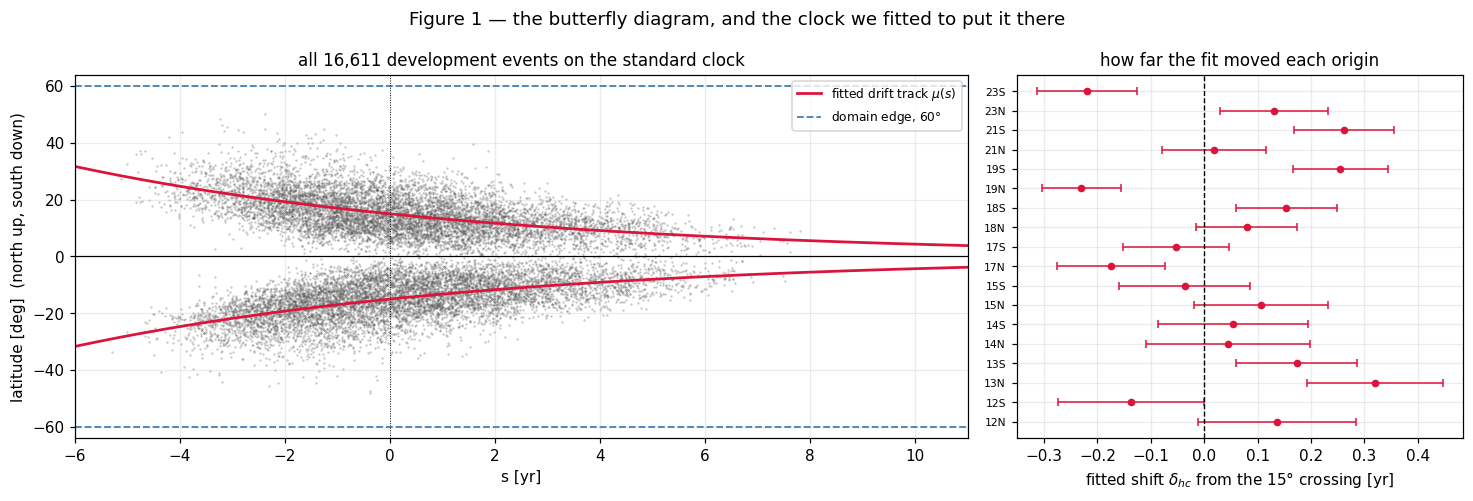

In [20]:
# Given: Figure 1 — the butterfly diagram we are about to model, on the standard clock.
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6),
                         gridspec_kw=dict(width_ratios=[2.0, 1.0]))

ax = axes[0]
sign = np.where(dev["hemisphere"].to_numpy() == "north", 1.0, -1.0)
ax.scatter(dev["s"], sign * dev["abs_latitude"], s=2.2, c="0.35", alpha=0.35, linewidths=0)
mu_curve = MU_REF * np.exp(-S_2D / alignment["mu_b"])
ax.plot(S_2D, mu_curve, color="crimson", lw=1.8, label=r"fitted drift track $\mu(s)$")
ax.plot(S_2D, -mu_curve, color="crimson", lw=1.8)
ax.axhline(LAM_MAX, color="steelblue", lw=1.2, ls="--", label=f"domain edge, {LAM_MAX:.0f}$°$")
ax.axhline(-LAM_MAX, color="steelblue", lw=1.2, ls="--")
ax.axhline(0.0, color="k", lw=0.8)
ax.axvline(0.0, color="k", lw=0.6, ls=":")
ax.set_xlim(S_A, S_B)
ax.set_ylim(-LAM_MAX - 4, LAM_MAX + 4)
ax.set_xlabel("s [yr]")
ax.set_ylabel("latitude [deg]  (north up, south down)")
ax.set_title(f"all {len(dev):,} development events on the standard clock")
ax.legend(fontsize=8, loc="upper right")

ax = axes[1]
ax.errorbar(origins["delta"], np.arange(len(origins)), xerr=origins["delta_se"],
            fmt="o", ms=4, color="crimson", capsize=2.5, lw=1.0)
ax.axvline(0.0, color="k", lw=0.9, ls="--")
ax.set_yticks(np.arange(len(origins)))
ax.set_yticklabels(origins.index, fontsize=7)
ax.set_xlabel(r"fitted shift $\delta_{hc}$ from the 15$°$ crossing [yr]")
ax.set_title("how far the fit moved each origin")
fig.suptitle("Figure 1 — the butterfly diagram, and the clock we fitted to put it there")
plt.tight_layout()
plt.show()

Three things to read off Figure 1.

The wings are obvious and the domain is comfortable: the highest-latitude development event is at about
50°, and the drift track plus a few degrees of spread stays well inside the 60° edge. That matters because
the model's own mass has to fit inside the domain we integrate over, not just the data.

The fitted shifts are small — a few tenths of a year — and their error bars are about 0.1 yr, so they are
*marginally* resolved: real, but not sharply. That is an honest limitation of fitting an origin to a
latitude track, and the arithmetic says why. The track falls at roughly 1.8° per year near `s` = 0, so a
shift of 0.3 yr moves it by about half a degree, against roughly 6° of intrinsic scatter in where groups
emerge. One event constrains the origin very weakly; it takes all 900 of them to get to 0.1 yr.

And the fitted origins sit about 0.8 yr later than 1.0's. Most of that is the crossing itself, which comes
out about 0.5 yr later than 1.0's epoch, and the rest is the fitted shift. *So every time in this notebook
is about 0.8 yr earlier in `s` than the same event was last week.* If you compare a number here against
your Week 2 notebook and it has moved by roughly that much, the clock moved, not the Sun.

---
## 3 · From a rate to a belt

*Given code — no tasks. Three short demonstrations that set up the rest of the notebook.*

Week 2 fitted the rate directly: λ(s) was the model, and its gamma shape was chosen because it looked
like the data. Nothing in it referred to the Sun. This week the rate becomes a *consequence*.

The picture is the standard one for the solar cycle. Somewhere below the surface sits a band of toroidal
magnetic field — wound up by differential rotation, drifting towards the equator as the cycle proceeds.
A piece of that band becomes buoyant and rises to form a sunspot group only once its field exceeds a
critical strength. Below that strength, nothing emerges. That cutoff is the **buoyancy threshold**.

We write the field as a Gaussian band in latitude whose centre follows the drift track:

```
B(|lat|, s) = A(s) * exp( -(|lat| - mu(s))^2 / (2 w^2) )
A(s)        = a_hc * g(s)                 g normalized to peak 1
mu(s)       = mu_a * exp(-s / mu_b)
```

`a_hc` is the peak field strength of that hemicycle's belt, `g(s)` is the shared time profile (Week 2's
gamma shape, with its onset fixed at the start of the window — the threshold will produce the onset, so
we no longer fit one), and `w` is the **belt width**, the latitudinal thickness of the band in degrees.

`B` is a **latent variable**: a quantity the model needs, that no instrument in this program ever measures.
We never see `B`. We see events, and we only ever learn about `B` through whatever turns it into events.

That "whatever" is the **emission function**, and it is where the threshold lives:

```
Lambda(|lat|, s) = c * softplus( B - B_crit )^alpha,       softplus(x) = log(1 + e^x)
```

Below critical, `softplus` is small and falls off exponentially, so almost nothing emerges. Above
critical it grows like `B - B_crit`, so emergence scales with the *excess* field. `softplus` rather than
a hard cut because it is smooth, and from Week 5 we will need derivatives.

### Three conventions, and why they are not free

`B_crit = 1`, `alpha = 1`, and `c` is one global scalar shared by every hemicycle. These are not tidying
up. The first demonstration below shows what happens without them.

In [21]:
# Given: the belt and the emission in one dimension, so we can compare against Week 2 directly.
def time_shape(s, k, theta):
    """g(s): Week 2's gamma shape with its onset at S_A, normalized to peak 1."""
    x = np.atleast_1d(np.asarray(s, dtype=float)) - S_A
    peak = (k - 1.0) * theta
    out = np.zeros_like(x)
    live = x > 0.0
    with np.errstate(over="ignore", invalid="ignore"):
        out[live] = (x[live] / peak) ** (k - 1.0) * np.exp(-(x[live] - peak) / theta)
    return out


def softplus(x):
    with np.errstate(invalid="ignore"):
        return np.logaddexp(0.0, np.asarray(x, dtype=float))


def belt_rate_1d(s, a, k, theta, c, b_crit=B_CRIT):
    """The 1D latent belt read out through the emission: no latitude, just B(s) = a g(s)."""
    return c * softplus(a * time_shape(s, k, theta) - b_crit) ** ALPHA


def fit_belt_1d(event_s, free_b_crit=False, start=None, restarts=3):
    """Maximum likelihood fit of the 1D belt. With `free_b_crit`, B_crit is fitted too."""
    event_s = np.sort(np.asarray(event_s, dtype=float))

    def negative_log_likelihood(p):
        a, k, theta, c = np.exp(p[0]), 1.0 + np.exp(p[1]), np.exp(p[2]), np.exp(p[3])
        b_crit = np.exp(p[4]) if free_b_crit else B_CRIT
        value = log_likelihood(event_s, lambda s: belt_rate_1d(s, a, k, theta, c, b_crit))
        return -value if np.isfinite(value) else 1e12

    p = np.array([np.log(2e4), np.log(6.0), np.log(0.9), np.log(5e-3), 0.0]) \
        if start is None else np.array(start, dtype=float)
    for _ in range(restarts):
        out = minimize(negative_log_likelihood, p, method="Nelder-Mead",
                       options=dict(maxiter=8000, maxfev=8000, xatol=1e-9, fatol=1e-9))
        p = out.x
    return out

In [22]:
# Given: demonstration 1 — the belt in 1D against Week 2's direct rate, on the same events, the same
# window and the same mesh. Both are one-dimensional likelihoods, so these two numbers *are* comparable.
DEMO = "19N"
demo_s = np.sort(EVENTS[DEMO][1])

q_gamma, s_first_gamma = fit_hemicycle(demo_s)
ll_gamma = log_likelihood(demo_s, lambda s: gamma_rate(s, q_gamma, s_first_gamma))

belt_fit = fit_belt_1d(demo_s)
a_belt, k_belt, theta_belt, c_belt = (np.exp(belt_fit.x[0]), 1.0 + np.exp(belt_fit.x[1]),
                                      np.exp(belt_fit.x[2]), np.exp(belt_fit.x[3]))
ll_belt = -belt_fit.fun

print(f"{DEMO}, {len(demo_s)} events, four fitted parameters each:")
print(f"   Week 2 direct rate : log L {ll_gamma:10.3f}")
print(f"   latent belt        : log L {ll_belt:10.3f}   "
      f"(a = {a_belt:.1f} x critical, c = {c_belt:.3f})")
print(f"   difference         : {ll_belt - ll_gamma:+.2f} nats in favour of the belt")
print("\nSo in one dimension the threshold model is not a sacrifice: it fits the times at least as well as")
print("a rate chosen to look like the data, and it has a reason for its shape.")

19N, 1590 events, four fitted parameters each:
   Week 2 direct rate : log L   6791.745
   latent belt        : log L   6793.898   (a = 240.6 x critical, c = 1.352)
   difference         : +2.15 nats in favour of the belt

So in one dimension the threshold model is not a sacrifice: it fits the times at least as well as
a rate chosen to look like the data, and it has a reason for its shape.


In [23]:
# Given: demonstration 2 — the gauge. Fit the same model with B_crit free, from two initializations that
# differ by a factor of 100 in the field strength.
gauge = {}
for kappa in (1.0, 100.0):
    start = [np.log(2e4 * kappa), np.log(6.0), np.log(0.9), np.log(5e-3 / kappa), np.log(kappa)]
    out = fit_belt_1d(demo_s, free_b_crit=True, start=start)
    a_g, c_g, b_g = np.exp(out.x[0]), np.exp(out.x[3]), np.exp(out.x[4])
    gauge[kappa] = dict(log_L=-out.fun, a=a_g, b_crit=b_g, c=c_g, ratio=a_g / b_g, p=out.x)
    print(f"start x{kappa:<6.0f} ->  log L {-out.fun:14.6f}   a {a_g:12.5g}   "
          f"B_crit {b_g:11.4g}   c {c_g:12.5g}   a / B_crit {a_g / b_g:8.3f}")

difference = abs(gauge[1.0]["log_L"] - gauge[100.0]["log_L"])
print(f"\nThe two fits differ by {difference:.2e} nats — they are the same fit.")
print(f"Their peak field strengths differ by a factor of {gauge[1.0]['a'] / gauge[100.0]['a']:.2f}, "
      f"their thresholds by the same factor,")
print(f"and the ratio a / B_crit agrees to {abs(gauge[1.0]['ratio'] - gauge[100.0]['ratio']):.1e}.")
print("The data determines how far above critical the belt is. It does not determine either number alone.")

start x1      ->  log L    6810.056572   a   2.7303e+06   B_crit   1.971e+05   c   0.00012005   a / B_crit   13.852
start x100    ->  log L    6810.056572   a   6.5464e+06   B_crit   4.726e+05   c    5.007e-05   a / B_crit   13.852

The two fits differ by 9.09e-13 nats — they are the same fit.
Their peak field strengths differ by a factor of 0.42, their thresholds by the same factor,
and the ratio a / B_crit agrees to 2.1e-06.
The data determines how far above critical the belt is. It does not determine either number alone.


That is the gauge argument, and it is the reason `B_crit` is fixed rather than fitted. Multiply `B` and
`B_crit` by the same factor and divide `c` by it, and a hard threshold gives back *exactly* the same
intensity — same predictions, same likelihood, different parameters. A quantity reported from a model
with a flat direction like that is not a measurement; it is a record of where the optimizer stopped.

One honest complication, because it will bite anyone who looks closely. `softplus` has a built-in
transition scale: it bends over a range of about 1 in whatever units `B` is in. So rescaling `B` is
*almost* but not *exactly* a relabeling — it also changes how sharp the threshold is relative to the belt's
own amplitude. Setting `B_crit = 1` therefore does two things at once: it fixes the units of `B`, so that
`a_hc` reads directly as "multiples of critical", and it ties the sharpness of the threshold to the belt
amplitude. The second part is a modelling commitment, not bookkeeping, and the cell above measures its
price: letting `B_crit` float buys about 16 nats on this wing. We take the convention anyway, because an
unidentifiable field strength is worth less than 16 nats — but we say so rather than pretend it is free.

`alpha = 1` is fixed for a related reason. Far above critical the emission becomes
`Lambda ≈ c * a_hc^alpha * g(s)^alpha * exp(-alpha * (|lat| - mu)^2 / 2w^2)`, which is a Gaussian of width
`w / sqrt(alpha)`. So `alpha` and the belt width are the same parameter wearing different hats, and fitting
both measures neither. And `c` is global because it is the one parameter that simply multiplies `Lambda`:
Section 5 shows it has a closed form, which is a gift rather than a constraint.

In [24]:
# Given: demonstration 3 — what a threshold predicts that a rate cannot. Take two consecutive hemicycles
# whose belts both peak *below* critical, place them 11 years apart, and add their fields.
weak_s = np.linspace(S_A, S_B + 11.0, 4000)
k_w, theta_w, c_w = k_belt, theta_belt, c_belt

floor_level = float(c_w * softplus(-B_CRIT) ** ALPHA)
floor_total = floor_level * (weak_s[-1] - weak_s[0])
print(f"the softplus floor: a belt of zero field still emits {floor_level:.4f} events/yr, which is")
print(f"{floor_total:.1f} events over the {weak_s[-1] - weak_s[0]:.0f}-year span below. Subtract it to see the")
print("threshold emission on its own.\n")
print("two consecutive hemicycles, both below critical, against a direct rate model scaled down by the")
print("same factor:\n")
for a_weak in (0.95, 0.80, 0.60):
    field = a_weak * time_shape(weak_s, k_w, theta_w) + a_weak * time_shape(weak_s - 11.0, k_w, theta_w)
    emitted = c_w * softplus(field - B_CRIT) ** ALPHA
    expected_belt = float(trapezoid(emitted, weak_s))
    # the comparison: Week 2's fitted rate for this wing, scaled by the same amplitude factor, twice
    scaled_rate = a_weak * gamma_rate(S_MESH, q_gamma, s_first_gamma)
    expected_rate = 2.0 * float(trapezoid(scaled_rate, S_MESH))
    print(f"   peak field {a_weak:.2f} x critical   max(B1 + B2) = {field.max():.3f}   "
          f"belt expects {expected_belt:7.2f} events, of which {expected_belt - floor_total:5.2f} is "
          f"threshold emission   ·   direct rate expects {expected_rate:6.0f}")

print(f"\nA 5% shortfall in field strength turns three thousand expected groups into a handful: a factor of")
print("roughly two hundred, and most of what survives is the floor rather than emergence. A direct rate")
print("model cannot do this — halve its amplitude and you get half the events, never a handful. This is the")
print("one prediction that distinguishes the two models, and cycles 12-23 are all far above critical, so it")
print("is a statement about a regime this catalog does not contain rather than a result we can check here.")

the softplus floor: a belt of zero field still emits 0.4235 events/yr, which is
11.9 events over the 28-year span below. Subtract it to see the
threshold emission on its own.

two consecutive hemicycles, both below critical, against a direct rate model scaled down by the
same factor:

   peak field 0.95 x critical   max(B1 + B2) = 0.952   belt expects   16.19 events, of which  4.33 is threshold emission   ·   direct rate expects   3021
   peak field 0.80 x critical   max(B1 + B2) = 0.801   belt expects   15.38 events, of which  3.52 is threshold emission   ·   direct rate expects   2544
   peak field 0.60 x critical   max(B1 + B2) = 0.601   belt expects   14.37 events, of which  2.51 is threshold emission   ·   direct rate expects   1908

A 5% shortfall in field strength turns three thousand expected groups into a handful: a factor of
roughly two hundred, and most of what survives is the floor rather than emergence. A direct rate
model cannot do this — halve its amplitude and you get h

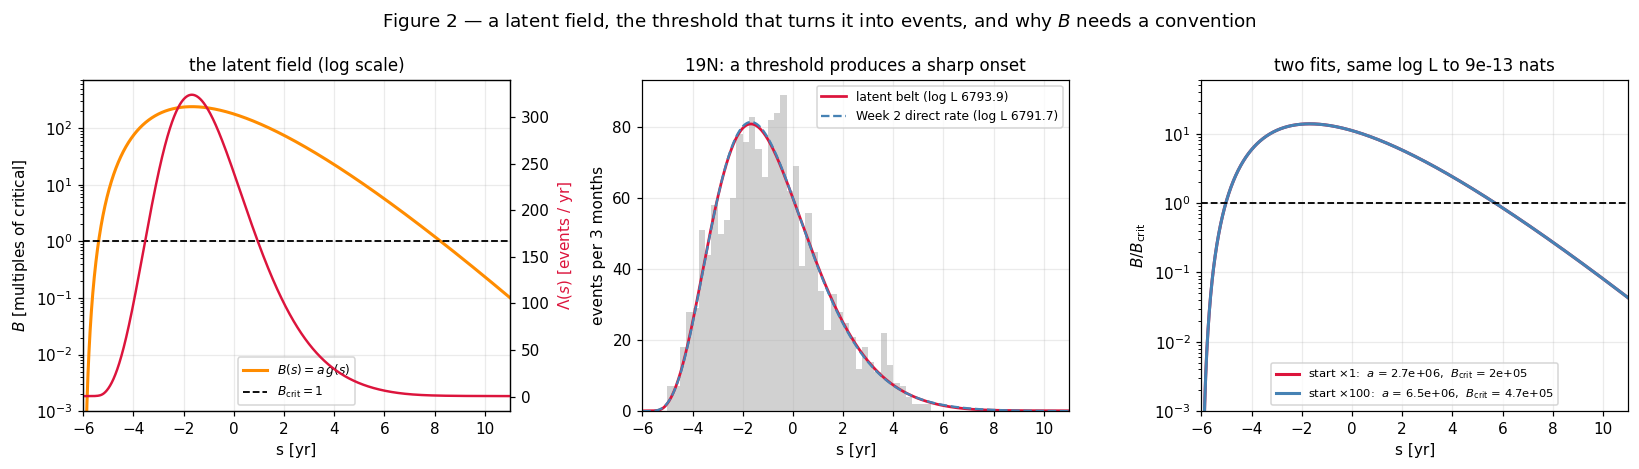

In [25]:
# Given: Figure 2 — the field, the emission, and the two things the demonstrations above showed.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

ax = axes[0]
field_demo = a_belt * time_shape(S_MESH, k_belt, theta_belt)
ax.plot(S_MESH, field_demo, color="darkorange", lw=2, label=r"$B(s) = a\,g(s)$")
ax.axhline(B_CRIT, color="k", lw=1.2, ls="--", label=r"$B_{\rm crit} = 1$")
ax.set_yscale("log")
ax.set_ylim(1e-3, field_demo.max() * 3)
ax.set_xlim(S_A, S_B)
ax.set_xlabel("s [yr]")
ax.set_ylabel(r"$B$ [multiples of critical]")
ax.set_title("the latent field (log scale)")
ax.legend(fontsize=8, loc="lower center")
twin = ax.twinx()
twin.plot(S_MESH, belt_rate_1d(S_MESH, a_belt, k_belt, theta_belt, c_belt),
          color="crimson", lw=1.6)
twin.set_ylabel(r"$\Lambda(s)$ [events / yr]", color="crimson")
twin.grid(False)

ax = axes[1]
bin_width = 0.25
ax.hist(demo_s, bins=np.arange(S_A, S_B + bin_width, bin_width), color="0.82", edgecolor="none")
ax.plot(S_MESH, belt_rate_1d(S_MESH, a_belt, k_belt, theta_belt, c_belt) * bin_width,
        color="crimson", lw=1.8, label=f"latent belt (log L {ll_belt:.1f})")
ax.plot(S_MESH, gamma_rate(S_MESH, q_gamma, s_first_gamma) * bin_width,
        color="steelblue", lw=1.5, ls="--", label=f"Week 2 direct rate (log L {ll_gamma:.1f})")
ax.set_xlim(S_A, S_B)
ax.set_xlabel("s [yr]")
ax.set_ylabel(f"events per {bin_width * 12:.0f} months")
ax.set_title(f"{DEMO}: a threshold produces a sharp onset")
ax.legend(fontsize=8)

ax = axes[2]
for kappa, colour in zip((1.0, 100.0), ("crimson", "steelblue")):
    g = gauge[kappa]
    a_g, k_g, th_g = g["a"], 1.0 + np.exp(g["p"][1]), np.exp(g["p"][2])
    ax.plot(S_MESH, a_g * time_shape(S_MESH, k_g, th_g) / g["b_crit"], color=colour, lw=2,
            label=f"start $\\times${kappa:.0f}:  $a$ = {a_g:.2g},  $B_{{\\rm crit}}$ = {g['b_crit']:.2g}")
ax.axhline(1.0, color="k", lw=1.2, ls="--")
ax.set_xlim(S_A, S_B)
ax.set_yscale("log")
ax.set_ylim(1e-3, 60)
ax.set_xlabel("s [yr]")
ax.set_ylabel(r"$B / B_{\rm crit}$")
ax.set_title(f"two fits, same log L to {difference:.0e} nats")
ax.legend(fontsize=7.5, loc="lower center")
fig.suptitle("Figure 2 — a latent field, the threshold that turns it into events, and why "
             r"$B$ needs a convention")
plt.tight_layout()
plt.show()

### Dialogue for Section 3 — a field you never observe

Nothing to write here. The block below steers the conversation you have with your tutor before you
implement anything in Section 4.

```text
TUTOR DIRECTIVE — Section 3. Work this before the student implements Tasks 22 to 24.

Material: the student has just read that emergence is modelled as a threshold on a latent magnetic belt,
B(|lat|, s) = a_hc g(s) exp(-(|lat| - mu(s))^2 / 2w^2), read out through Lambda = c softplus(B - B_crit)^alpha
with B_crit = 1, alpha = 1 and c global. Section 3's cells have been run; Sections 4 onwards have not,
and the student is about to write the field, the emission and the two-dimensional likelihood.

Hold the student to the destinations below, through their own reformulation rather than your exposition.

1. What makes B a latent variable rather than just another parameter. Require the student to say what
   would have to be true for B to be an observable, and what the model would look like if we could
   measure it. Then ask what we actually learn about B from a catalog of emergence times and latitudes.
   Do not let "latent means hidden" stand as an answer; push for the consequence.
2. The gauge. Before looking at the figure, require the student to construct a change to B that leaves
   every prediction identical. Bridge via "suppose I multiply B by ten — what else must change, and is
   there anything left over?" Do not supply the transformation, and do not name the combination that
   survives: make them find that something survives, and say what it is.
3. Then the distinction that matters: a flat direction because the model is over-described, versus a flat
   direction because the data is weak. They met the second kind in Week 02, where the onset sat on the
   window edge in most hemicycles, and their HANDOFF should have it. Ask what you do about each. Require
   them to notice that one is fixed by choosing and the other is not.
4. A prediction, committed to before they see it. Two consecutive hemicycles whose belts both peak just
   below critical: what does a threshold model say about how many groups emerge, and what does a model
   that fits the rate directly say about the same two cycles? Require a number or a ratio, not a
   direction. Then ask which observable would distinguish the two models, and whether the historical
   record contains such an observable. Do not name any historical episode; let them get there or not.
5. Finally, the move to two dimensions. Ask what changes in the likelihood when the intensity gains a
   second argument, and what the integral term becomes. Require them to say what the units of Lambda are
   and why that makes this week's log-likelihood incomparable with last week's number.

`latent variable`, `gauge freedom` and `emission function` are the targets least likely to have been
deployed by this point; prefer them when you choose an anchor.
```

---
## 4 · The intensity surface, and a second quadrature direction

Now latitude. The object we fit is no longer a curve but an **intensity surface** Λ(|λ|, s): the expected
number of emergences per degree of latitude per year, at every point of the window. The likelihood keeps
exactly the shape it had in Week 2 —

```
log L = sum_i log Lambda(|lat_i|, s_i)  -  integral over lat, s of Lambda
```

— and the only change is that the integral is now a double one, over the latitude domain as well as the
time window. The loss is the same loss. Week 5's neural field is trained on this same expression.

Three things to be careful about, and they all come from the second dimension.

### The units changed, so the number is not comparable with last week's

λ(s) was events per year. Λ(|λ|, s) is events per degree per year — a different quantity, numerically
much smaller, so `log Λ` at an event is smaller than `log λ` was. This week's log-likelihood per
hemicycle-year will come out around −27 where Week 2's was −204, for models of the same data, and *neither
number says the model is better.* They are scores on different quantities. Do not put a 1D and a 2D
log-likelihood in the same column; to compare across the two, Section 7 uses a statistic with no units.

### The equator is a real boundary

Within one hemisphere, |latitude| runs from 0 up. The domain is `|λ| ∈ [0°, 60°]`, and 0 is a wall, not a
convenience. ButterflAI 1.0 modelled the latitude distribution as a probability *density* and let its
Gaussian extend below the equator, which leaked about 1% of its mass to latitudes that do not exist in
that hemisphere — mass that should have been renormalized away and was not.

We inherit no such problem, and it is worth being clear why. Λ is an *intensity*, not a density: it does
not have to integrate to 1, so truncating the domain at the equator requires no renormalization at all.
The model simply predicts fewer events, the integral term accounts for exactly the events it predicts
inside the domain, and the likelihood stays correct. This is the practical payoff of having moved from a
normalized density to an intensity back in Week 2.

The upper edge is a choice, and the criterion is that the domain must contain *the model*, not just the
data. The highest-latitude development event is near 50°, but the drift track starts at about 34° at
`s` = −6 with several degrees of belt width on top, so the belt's own tail reaches into the fifties. 60°
leaves room for it.

### The mesh is now two-dimensional, and it is frozen here

The **quadrature mesh** is the grid on which we evaluate Λ to approximate its integral. Week 2 fixed the
time axis at 4001 nodes and justified it by being finer than the catalog's one-day quantization. That
criterion does not transfer: a mesh fine enough to resolve a 0.1° latitude measurement would be 601 nodes
wide and we would be integrating 2.4 million points per likelihood call for no benefit, because *the
integrand's own feature scale is the belt width of about 6°, not the precision of the measurement.*

So we use the criterion that always works and that Week 2 also used: refine and watch. The cells below do
that in each direction separately, and the answer is lopsided enough to be worth knowing before you
choose. The result is `201 × 241` nodes — 31 days in time, 0.25° in latitude — and it is fixed from here
through Scoreboard 1. Resolution is a knob only in Phase B.

In [26]:
raise NotImplementedError("Task 22: The latent belt as a surface over latitude and time")
# Reference workflow:
#   1. Write `drift(s, mu_a, mu_b)` for the exponential track mu_a * exp(-s / mu_b). One line.
#   2. In `belt_field`, evaluate the track at `s`, then the offset of each latitude from it.
#   3. Multiply the amplitude `a_hc`, the shared time profile `time_shape(s, k, theta)` from Section 3, and
#      the Gaussian in that offset with standard deviation `width`.
#   4. Do not assume `width` is a number: write the expression so it also works when `width` is an array
#      the same shape as `mu`. And write nothing that assumes `abs_lat` and `s` have the same shape — the
#      next task evaluates this on a mesh, as a column of latitudes against a row of times.
#   Name them `drift(s, mu_a, mu_b)` and
#   `belt_field(abs_lat, s, a_hc, k, theta, mu_a, mu_b, width)`.

NotImplementedError: Task 22: The latent belt as a surface over latitude and time

In [42]:
def drift(s, mu_a, mu_b):
    """Exponential drift track of the active belt toward the equator."""
    return mu_a * np.exp(-s / mu_b)


def belt_field(abs_lat, s, a_hc, k, theta, mu_a, mu_b, width):
    """Evaluate the latent magnetic field B(|lat|, s).

    Supports broadcasting when abs_lat is a column (N_lat x 1) and s is a row (1 x N_s).
    """
    mu = drift(s, mu_a, mu_b)
    profile = time_shape(s, k, theta)

    # Calculate the Gaussian spatial offset profile in latitude
    offset = abs_lat - mu
    spatial_profile = np.exp(- (offset ** 2) / (2.0 * width ** 2))

    # Total latent field combines amplitude, time profile, and spatial profile
    return a_hc * profile * spatial_profile

In [43]:
raise NotImplementedError("Task 23: The emission, with the gauge fixed")
# Reference workflow:
#   1. Evaluate the field with Task 22.
#   2. Subtract `B_CRIT`, apply the `softplus` from Section 3, raise to the power `ALPHA`, multiply by `c`.
#   3. Use the module-level `B_CRIT` and `ALPHA` rather than passing them in. That is the point of fixing
#      them: they are not parameters of this model, they are conventions of this program.
#   Name it `intensity_2d(abs_lat, s, a_hc, k, theta, mu_a, mu_b, width, c)`.

NotImplementedError: Task 23: The emission, with the gauge fixed

In [44]:
def intensity_2d(abs_lat, s, a_hc, k, theta, mu_a, mu_b, width, c):
    """Evaluate the 2D intensity surface Lambda(|lat|, s) in events/degree/year.

    Uses program-wide conventions: B_CRIT = 1.0, ALPHA = 1.0.
    """
    # 1. Evaluate the latent field
    B = belt_field(abs_lat, s, a_hc, k, theta, mu_a, mu_b, width)

    # 2. Subtract B_CRIT, apply softplus, raise to ALPHA, and scale by c
    return c * (softplus(B - B_CRIT) ** ALPHA)

In [45]:
# Given: a small amount of bookkeeping that the rest of the notebook leans on. The shared parameters
# travel together in one dict, and `make_intensity` closes over them to give the plain function of
# (latitude, time) that the likelihood wants. `width_fn` lets Section 8 swap the width rule without
# touching anything else; until then it is a constant.
def width_constant(mu, a_hc, params):
    return params[0]


def make_intensity(a_hc, shared):
    """A function of (|lat|, s) for one hemicycle, given its amplitude and the shared parameters."""
    def intensity(abs_lat, s):
        mu = drift(s, shared["mu_a"], shared["mu_b"])
        width = shared["width_fn"](mu, a_hc, shared["width_params"])
        return intensity_2d(abs_lat, s, a_hc, shared["k"], shared["theta"],
                            shared["mu_a"], shared["mu_b"], width, shared["c"])
    return intensity


def shared_parameters(k, theta, mu_a, mu_b, width_params, c, width_fn=width_constant):
    return dict(k=k, theta=theta, mu_a=mu_a, mu_b=mu_b,
                width_params=list(width_params), c=c, width_fn=width_fn)


DEMO_SHARED = shared_parameters(k=7.7, theta=0.82, mu_a=14.6, mu_b=7.2, width_params=[6.5], c=5.0e-4)
print("a demonstration parameter set, before anything is fitted:")
print({key: value for key, value in DEMO_SHARED.items() if key != "width_fn"})

a demonstration parameter set, before anything is fitted:
{'k': 7.7, 'theta': 0.82, 'mu_a': 14.6, 'mu_b': 7.2, 'width_params': [6.5], 'c': 0.0005}


In [46]:
raise NotImplementedError("Task 24: The two-dimensional log-likelihood on the fixed mesh")
# Reference workflow:
#   1. Write `integrate_2d`: `scipy.integrate.trapezoid` twice, first down the latitude axis and then along
#      the time axis, passing the node positions each time so the spacing is never assumed.
#   2. In `log_likelihood_2d`, evaluate the intensity at the observed (latitude, time) pairs. If any of
#      those is zero, negative or not finite, the model called an observed event impossible: return -inf,
#      exactly as in Week 2.
#   3. Evaluate the intensity on the mesh as a 2D array. Pass the latitudes as a column and the times as a
#      row and let numpy broadcast; the result is (n_latitude, n_time), which is the layout step 1 expects.
#   4. Return the sum of logs at the events minus the integral, as a plain float, guarding against a
#      non-finite total. The window and the domain are set by the mesh, not by the data.
#   Name them `integrate_2d(values, mesh=MESH_2D)` and
#   `log_likelihood_2d(event_lat, event_s, intensity_fn, mesh=MESH_2D)`.

NotImplementedError: Task 24: The two-dimensional log-likelihood on the fixed mesh

In [47]:
def integrate_2d(values, mesh=MESH_2D):
    """Compute double integral using trapezoidal rule first over latitude then over time."""
    s_mesh, lam_mesh = mesh
    # values is of shape (n_latitude, n_time)
    # First integrate along latitude axis (axis 0)
    int_lat = trapezoid(values, lam_mesh, axis=0)
    # Then integrate along time axis (axis 0 now that axis 1 became axis 0)
    return float(trapezoid(int_lat, s_mesh))


def log_likelihood_2d(event_lat, event_s, intensity_fn, mesh=MESH_2D):
    """Compute the inhomogeneous 2D Poisson process log-likelihood."""
    # 1. Evaluate intensity at the observed event locations
    rates = intensity_fn(event_lat, event_s)
    if not np.all(np.isfinite(rates)) or np.any(rates <= 0.0):
        return -np.inf

    # 2. Integrate the intensity surface over the 2D mesh
    s_mesh, lam_mesh = mesh
    # Grid evaluation using broadcasting: column of lats (N_lat x 1) vs row of times (1 x N_s)
    grid_values = intensity_fn(lam_mesh[:, None], s_mesh[None, :])
    integral = integrate_2d(grid_values, mesh)

    # 3. Sum of logs minus the total integrated intensity
    total = float(np.sum(np.log(rates)) - integral)
    return total if np.isfinite(total) else -np.inf

In [48]:
# Given: check the ruler before measuring with it. For a *constant* intensity Lambda0 over the whole domain
# the log-likelihood is n log(Lambda0) - Lambda0 * area, exactly.
demo_lat, demo_s_2d = EVENTS[DEMO]
area = WINDOW_YEARS * LAM_MAX
for lam0 in (0.5, len(demo_lat) / area, 2.0):
    numeric = log_likelihood_2d(demo_lat, demo_s_2d, lambda la, s: np.full(np.broadcast(la, s).shape, lam0))
    analytic = len(demo_lat) * np.log(lam0) - lam0 * area
    print(f"Lambda0 = {lam0:6.3f} /deg/yr   numeric {numeric:12.4f}   analytic {analytic:12.4f}   "
          f"difference {numeric - analytic:+.2e}")
assert abs(log_likelihood_2d(demo_lat, demo_s_2d, lambda la, s: np.full(np.broadcast(la, s).shape, 1.0))
           - (-1.0 * area)) < 1e-6
print(f"\ndomain area = {area:.0f} deg*yr")

Lambda0 =  0.500 /deg/yr   numeric   -1612.1040   analytic   -1612.1040   difference +0.00e+00
Lambda0 =  1.559 /deg/yr   numeric    -884.1491   analytic    -884.1491   difference -2.84e-12
Lambda0 =  2.000 /deg/yr   numeric    -937.8960   analytic    -937.8960   difference +4.55e-13

domain area = 1020 deg*yr


In [49]:
# Given: refine the mesh in each direction separately and watch. The reference is a mesh far finer than
# anything we would use. We never compare against an exact answer — there is none.
REFERENCE_MESH = (np.linspace(S_A, S_B, 1601), np.linspace(0.0, LAM_MAX, 641))


def demo_integral(mesh, a_hc=2.0e4, shared=DEMO_SHARED):
    s_mesh, lam_mesh = mesh
    return integrate_2d(make_intensity(a_hc, shared)(lam_mesh[:, None], s_mesh[None, :]), mesh)


reference = demo_integral(REFERENCE_MESH)
print(f"reference expected count: {reference:.6f} events\n")

print("refining time, with latitude held at 0.25 deg:")
for n_s in (51, 101, 201, 401, 801):
    value = demo_integral((np.linspace(S_A, S_B, n_s), LAM_2D))
    print(f"   {n_s:5d} nodes  ds = {(S_B - S_A) / (n_s - 1) / ONE_DAY:5.1f} d   "
          f"error {value - reference:+.4f} events")

print("\nrefining latitude, with time held at 31 d:")
for n_lam in (31, 61, 121, 241, 481):
    value = demo_integral((S_2D, np.linspace(0.0, LAM_MAX, n_lam)))
    print(f"   {n_lam:5d} nodes  dlat = {LAM_MAX / (n_lam - 1):5.3f} deg   "
          f"error {value - reference:+.4f} events")

print(f"\nour mesh, {N_S_2D} x {N_LAM_2D}: error "
      f"{demo_integral(MESH_2D) - reference:+.4f} events out of {reference:.0f}")

reference expected count: 851.956349 events

refining time, with latitude held at 0.25 deg:
      51 nodes  ds = 124.2 d   error -0.0101 events
     101 nodes  ds =  62.1 d   error -0.0088 events
     201 nodes  ds =  31.0 d   error -0.0086 events
     401 nodes  ds =  15.5 d   error -0.0085 events
     801 nodes  ds =   7.8 d   error -0.0085 events

refining latitude, with time held at 31 d:
      31 nodes  dlat = 2.000 deg   error -0.6295 events
      61 nodes  dlat = 1.000 deg   error -0.1565 events
     121 nodes  dlat = 0.500 deg   error -0.0381 events
     241 nodes  dlat = 0.250 deg   error -0.0086 events
     481 nodes  dlat = 0.125 deg   error -0.0012 events

our mesh, 201 x 241: error -0.0086 events out of 852


Read that carefully, because it is the whole argument for the mesh. *Refining time does essentially
nothing* — the error does not move between 51 nodes and 801. *Refining latitude is everything* — the error
falls by a factor of four at every halving of the spacing, which is what the trapezoid rule's second-order
accuracy predicts and is therefore evidence the quadrature is converging rather than merely settling.

The reason is feature scale. In time the integrand is the smooth gamma profile, which varies on a scale of
a year, so month-wide nodes resolve it completely. In latitude the integrand is a band about 6° wide whose
centre sweeps from 34° down to 4° across the window, so the spacing has to resolve the band.

That is why the mesh is `201 × 241` and not `401 × 121`: those two have the *same number of nodes* and
therefore the same cost, and spending them on latitude instead of time makes the integral four times more
accurate. The time axis is 201 nodes because it is exactly every twentieth node of Week 2's frozen
4001-node mesh, which keeps one grid rather than two unrelated ones.

### What a coarse mesh actually costs, which is not what people expect

A coarse mesh is usually described as making the fit inaccurate. It does something more specific and more
dangerous than that. The mesh enters only the *integral* term — the intensity at the events is evaluated
exactly — and the integral is *subtracted*. A mesh that under-counts `∫∫Λ` therefore makes every model
look better than it is. And it flatters sharper models more, because they are the ones a coarse grid
misses. So a quadrature error is not noise: it is a bias with a direction, available to any model willing
to put structure between the nodes.

The cell below measures it the only honest way: fit on a mesh, then score the fitted parameters on the
fine reference mesh, and look at the difference.

In [50]:
# Given: the three candidate meshes, and the integral error each one makes. Section 5 turns these into
# nats, once there is a fitted model to score.
MESH_CANDIDATES = {
    "101 x  31": (np.linspace(S_A, S_B, 101), np.linspace(0.0, LAM_MAX, 31)),
    "201 x  61": (np.linspace(S_A, S_B, 201), np.linspace(0.0, LAM_MAX, 61)),
    "201 x 241": MESH_2D,
}
for name, mesh in MESH_CANDIDATES.items():
    s_mesh, lam_mesh = mesh
    print(f"   {name}  = {len(s_mesh) * len(lam_mesh):6,d} nodes   "
          f"dlat {LAM_MAX / (len(lam_mesh) - 1):5.3f} deg   "
          f"integral error {demo_integral(mesh) - reference:+.4f} events")

   101 x  31  =  3,131 nodes   dlat 2.000 deg   integral error -0.6298 events
   201 x  61  = 12,261 nodes   dlat 1.000 deg   integral error -0.1565 events
   201 x 241  = 48,441 nodes   dlat 0.250 deg   integral error -0.0086 events


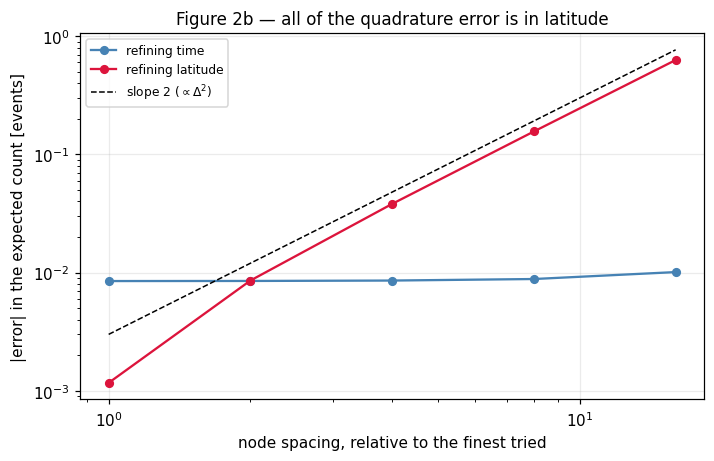

In [51]:
# Given: Figure 2b — the refinement, in both directions, on one pair of axes.
fig, ax = plt.subplots(figsize=(6.6, 4.3))
for axis_name, nodes, builder, colour in (
        ("time", (51, 101, 201, 401, 801), lambda n: (np.linspace(S_A, S_B, n), LAM_2D), "steelblue"),
        ("latitude", (31, 61, 121, 241, 481), lambda n: (S_2D, np.linspace(0.0, LAM_MAX, n)), "crimson")):
    spacing, error = [], []
    for n in nodes:
        mesh = builder(n)
        spacing.append((S_B - S_A) / (n - 1) if axis_name == "time" else LAM_MAX / (n - 1))
        error.append(abs(demo_integral(mesh) - reference))
    ax.loglog(np.array(spacing) / spacing[-1], error, "o-", color=colour, ms=5,
              label=f"refining {axis_name}")
guide = np.array([1.0, 16.0])
ax.loglog(guide, 3e-3 * guide ** 2, "k--", lw=1.0, label=r"slope 2 ($\propto \Delta^2$)")
ax.set_xlabel("node spacing, relative to the finest tried")
ax.set_ylabel("|error| in the expected count [events]")
ax.set_title("Figure 2b — all of the quadrature error is in latitude")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

---
## 5 · Pooling: one shape, eighteen amplitudes

Week 2 fitted each wing on its own and ended by measuring why that was the wrong thing to do: only about
one event in a thousand occurs before `s` = −4, so the rising edge of a wing is observed by a handful of
groups, and a single hemicycle cannot determine the shape it is drawn from.

The answer is **partial pooling**: share the parameters that describe the *shape* across all 18 wings, and
give each wing only the parameters that describe *its own* size. Here that split is clean:

| shared by all 18 hemicycles | one per hemicycle |
|---|---|
| `k`, `theta` — the time profile `g(s)` | `a_hc` — the peak belt field, in multiples of critical |
| `mu_a`, `mu_b` — the drift track | |
| `w` — the belt width | |
| `c` — the emission scale | |

Six shared numbers and eighteen amplitudes, against Week 2's seventy-two independent parameters. "Partial"
matters: full pooling would force every wing to have the same size, which is plainly false, and no pooling
is what Week 2 showed does not work.

### Two pieces of structure that make this cheap

*`c` has a closed form.* It is the only parameter that simply multiplies Λ, so
`d log L / d log c = n_total − ∫∫Λ`, and setting that to zero gives `c = n_total / ∫∫Λ` evaluated at
`c` = 1. We never hand `c` to an optimizer. Notice what this means: the fitted model predicts the total
number of events *exactly*, summed over all 18 hemicycles. It is Week 2's maximum-likelihood identity,
except that it now holds for the pool rather than for each wing — because `a_hc` sits inside a threshold
and is not a plain multiplier, so no individual wing's count is pinned. The per-hemicycle mismatch is
therefore something to look at, not something guaranteed to vanish.

*Given the shared parameters, the eighteen amplitudes are eighteen independent one-dimensional problems.*
Each hemicycle's contribution to the log-likelihood depends on its own `a_hc` and nothing else. So instead
of handing an optimizer 24 parameters at once, we alternate: fit the shape with the amplitudes held, refit
each amplitude on its own, solve for `c`, repeat. Three rounds is enough.

Note also what is *not* in the table: no per-hemicycle timing. The clock was fitted in Section 2 and `s`
is now standard, so a wing's only freedom is how strong it is.

In [52]:
raise NotImplementedError("Task 25: One hemicycle's amplitude, given the shared parameters")
# Reference workflow:
#   1. The amplitude must stay above the threshold to produce any events at all, and it ranges over orders
#      of magnitude, so optimize its logarithm inside bounds rather than the amplitude itself.
#   2. Write the objective: minus the Task 24 log-likelihood of this hemicycle's events under
#      `make_intensity(exp(log_a), shared)`. Return a large finite number if the likelihood is -inf.
#   3. This is one parameter, so use `scipy.optimize.minimize_scalar` with `method="bounded"` and the
#      bracket above — not a multidimensional optimizer.
#   4. Return the amplitude itself, not its log.
#   Name it `fit_hemicycle_amplitude(event_lat, event_s, shared, mesh=MESH_2D)`.

NotImplementedError: Task 25: One hemicycle's amplitude, given the shared parameters

In [53]:
def fit_hemicycle_amplitude(event_lat, event_s, shared, mesh=MESH_2D):
    """Find the optimum peak field amplitude a_hc for a single hemicycle.

    Optimizes the log-amplitude inside bounds using minimize_scalar.
    """
    # 1. Objective function: negative log-likelihood of this hemicycle's events
    def objective(log_a):
        a_hc = np.exp(log_a)
        intensity_fn = make_intensity(a_hc, shared)
        val = log_likelihood_2d(event_lat, event_s, intensity_fn, mesh=mesh)
        return -val if np.isfinite(val) else 1e12

    # 2. Bounded search range in log-space: from 0.0 (amplitude = 1) up to log(1e7)
    # The peak must be at least B_crit = 1 to produce any softplus excess
    bounds = (0.0, np.log(1e7))

    # 3. Optimize using bounded scalar minimization
    res = minimize_scalar(objective, bounds=bounds, method="bounded", options=dict(xatol=1e-12))

    # 4. Return the actual amplitude
    return float(np.exp(res.x))

In [54]:
raise NotImplementedError("Task 26: The pooled fit")
# Reference workflow:
#   1. Write `unpack_shared(q, ...)`: exponentials for `k - 1`, `theta`, `mu_a`, `mu_b` and the first width
#      parameter, and any further width parameters passed through unchanged (Section 8 needs one that may
#      be negative). Build it with `shared_parameters`. This is Week 2's unconstrained parameterization,
#      extended.
#   2. Write the closed form for `c`: integrate the intensity of every hemicycle with `c` = 1, add the
#      integrals up, and divide the total event count by the sum.
#   3. Write the shape objective: minus the sum over hemicycles of the Task 24 log-likelihood, with the
#      amplitudes and `c` held fixed. Return a large finite number if any hemicycle gives -inf.
#   4. Alternate `sweeps` times: minimize the shape objective over `q` with `scipy.optimize.minimize` and
#      `method="L-BFGS-B"`; then refit every amplitude with Task 25; then re-solve `c`. Return the shared
#      parameters, the amplitudes, and the achieved negative log-likelihood.
#   Name it `fit_pooled(events, labels, start=None, sweeps=3, width_fn=width_constant, n_width=1,
#   width_start=(6.5,), amplitude_start=None, mesh=MESH_2D)` and return a dict with keys `q`, `shared`,
#   `amplitudes`, `nll`, `labels`.

NotImplementedError: Task 26: The pooled fit

In [55]:
def unpack_shared(q, width_fn, c, n_width):
    """Convert unconstrained parameter vector q back to physical parameters."""
    # q elements:
    # q[0]: log(k - 1) -> k = 1 + exp(q[0])
    # q[1]: log(theta) -> theta = exp(q[1])
    # q[2]: log(mu_a) -> mu_a = exp(q[2])
    # q[3]: log(mu_b) -> mu_b = exp(q[3])
    # q[4]: log(w0) -> width_params[0] = exp(q[4])
    # subsequent elements of q are additional width parameters passed through directly
    k = 1.0 + np.exp(q[0])
    theta = np.exp(q[1])
    mu_a = np.exp(q[2])
    mu_b = np.exp(q[3])

    width_params = []
    if n_width > 0:
        width_params.append(np.exp(q[4]))
        for val in q[5:4+n_width]:
            width_params.append(val)

    return shared_parameters(k=k, theta=theta, mu_a=mu_a, mu_b=mu_b,
                             width_params=width_params, c=c, width_fn=width_fn)

In [56]:
def drift(s, mu_a, mu_b):
    """Exponential drift track of the active belt toward the equator."""
    return mu_a * np.exp(-s / mu_b)

def unpack_shared(q, width_fn, c, n_width):
    """Convert unconstrained parameter vector q back to physical parameters."""
    k = 1.0 + np.exp(q[0])
    theta = np.exp(q[1])
    mu_a = np.exp(q[2])
    mu_b = np.exp(q[3])

    width_params = []
    if n_width > 0:
        width_params.append(np.exp(q[4]))
        for val in q[5:4+n_width]:
            width_params.append(val)

    return shared_parameters(k=k, theta=theta, mu_a=mu_a, mu_b=mu_b,
                             width_params=width_params, c=c, width_fn=width_fn)

def width_constant(mu, a_hc, params):
    return params[0]

def shared_parameters(k, theta, mu_a, mu_b, width_params, c, width_fn=width_constant):
    return dict(k=k, theta=theta, mu_a=mu_a, mu_b=mu_b,
                width_params=list(width_params), c=c, width_fn=width_fn)

def make_intensity(a_hc, shared):
    def intensity(abs_lat, s):
        mu = drift(s, shared["mu_a"], shared["mu_b"])
        width = shared["width_fn"](mu, a_hc, shared["width_params"])
        return intensity_2d(abs_lat, s, a_hc, shared["k"], shared["theta"],
                            shared["mu_a"], shared["mu_b"], width, shared["c"])
    return intensity

def fit_pooled(events, labels, start=None, sweeps=3, width_fn=width_constant, n_width=1,
               width_start=(6.5,), amplitude_start=None, mesh=MESH_2D):
    """Coordinate ascent solver for the pooled model."""
    s_mesh, lam_mesh = mesh
    n_total_events = sum(len(events[h][0]) for h in labels)

    # 1. Initialize shared unconstrained parameter vector q
    if start is None:
        q = np.array([
            np.log(7.7 - 1.0),  # log(k - 1)
            np.log(0.82),       # log(theta)
            np.log(14.6),       # log(mu_a)
            np.log(7.2),        # log(mu_b)
            np.log(width_start[0]) # log(w0)
        ] + list(width_start[1:n_width]))
    else:
        q = np.array(start, dtype=float)

    # Initialize amplitudes
    if amplitude_start is None:
        amplitudes = {h: 2.0e4 for h in labels}
    else:
        amplitudes = dict(amplitude_start)

    c = 5.0e-4

    # Helper to calculate c analytically
    def solve_c(current_q, current_amps):
        temp_shared = unpack_shared(current_q, width_fn, 1.0, n_width)
        total_integrated = 0.0
        for h in labels:
            intensity_fn = make_intensity(current_amps[h], temp_shared)
            grid_vals = intensity_fn(lam_mesh[:, None], s_mesh[None, :])
            total_integrated += integrate_2d(grid_vals, mesh)
        return n_total_events / total_integrated

    # Coordinate ascent sweeps
    for sweep in range(sweeps):
        # --- Step A: Optimize shape parameters (q) with held amplitudes and scale c ---
        def shape_objective(q_try):
            shared_try = unpack_shared(q_try, width_fn, c, n_width)
            total_nll = 0.0
            for h in labels:
                intensity_fn = make_intensity(amplitudes[h], shared_try)
                val = log_likelihood_2d(events[h][0], events[h][1], intensity_fn, mesh=mesh)
                if not np.isfinite(val):
                    return 1e12
                total_nll -= val
            return total_nll

        res = minimize(shape_objective, q, method="L-BFGS-B", options=dict(maxiter=200))
        q = res.x

        # --- Step B: Optimize individual amplitudes (a_hc) given shared parameters ---
        shared_fixed = unpack_shared(q, width_fn, c, n_width)
        for h in labels:
            amplitudes[h] = fit_hemicycle_amplitude(events[h][0], events[h][1], shared_fixed, mesh=mesh)

        # --- Step C: Update global scale multiplier c analytically ---
        c = solve_c(q, amplitudes)

    # Final evaluations
    shared_final = unpack_shared(q, width_fn, c, n_width)
    final_nll = shape_objective(q)

    return {
        "q": q,
        "shared": shared_final,
        "amplitudes": amplitudes,
        "nll": final_nll,
        "labels": labels
    }

In [57]:
# Given: run it on all 18 development hemicycles. About 20 seconds.
POOLED = fit_pooled(EVENTS, DEV_HEMICYCLES, sweeps=3)
shared = POOLED["shared"]

print(f"shared time profile : k = {shared['k']:.3f}   theta = {shared['theta']:.4f} yr   "
      f"peak of g at s = {S_A + (shared['k'] - 1) * shared['theta']:+.3f}")
print(f"shared drift track  : mu_a = {shared['mu_a']:.3f} deg   mu_b = {shared['mu_b']:.3f} yr")
print(f"shared belt width   : w = {shared['width_params'][0]:.3f} deg")
print(f"emission scale      : c = {shared['c']:.5g} events / deg / yr")
print(f"belt amplitudes     : {min(POOLED['amplitudes'].values()):.4g} to "
      f"{max(POOLED['amplitudes'].values()):.4g} x critical")
print(f"\nlog-likelihood      : {-POOLED['nll']:.2f} nats over {len(dev):,} events")
print(f"negative log-likelihood per hemicycle-year: "
      f"{POOLED['nll'] / (len(DEV_HEMICYCLES) * WINDOW_YEARS):.3f}   (in sample)")
print("Remember: this is a 2D score and Week 2's -203.87 was a 1D score. They are not comparable.")

shared time profile : k = 7.684   theta = 0.8216 yr   peak of g at s = -0.508
shared drift track  : mu_a = 14.571 deg   mu_b = 7.203 yr
shared belt width   : w = 6.502 deg
emission scale      : c = 0.00050003 events / deg / yr
belt amplitudes     : 1.231e+04 to 3.73e+04 x critical

log-likelihood      : 8138.20 nats over 16,611 events
negative log-likelihood per hemicycle-year: -26.595   (in sample)
Remember: this is a 2D score and Week 2's -203.87 was a 1D score. They are not comparable.


In [58]:
# Given: the identity, and the per-hemicycle mismatch it does *not* guarantee.
predicted = {h: integrate_2d(make_intensity(POOLED["amplitudes"][h], shared)(
    LAM_2D[:, None], S_2D[None, :]), MESH_2D) for h in DEV_HEMICYCLES}

counts = pd.DataFrame({
    "observed": pd.Series(COUNTS),
    "predicted": pd.Series(predicted),
    "a_hc": pd.Series(POOLED["amplitudes"]),
    "A": amplitudes,
}).loc[DEV_HEMICYCLES]
counts["error %"] = 100.0 * (counts["predicted"] - counts["observed"]) / counts["observed"]

print(counts.to_string(float_format=lambda v: f"{v:12.3f}"))
print(f"\ntotal predicted {counts['predicted'].sum():.2f} vs observed {counts['observed'].sum()} "
      f"— the pooled identity, exact by construction")
assert abs(counts["predicted"].sum() - counts["observed"].sum()) < 1e-2
print(f"per-hemicycle error: {counts['error %'].min():+.2f}% to {counts['error %'].max():+.2f}%")

     observed    predicted         a_hc            A      error %
12N       525      524.937    12313.653        0.079       -0.012
12S       664      663.966    15573.643        0.149       -0.005
13N       716      715.961    16792.822        0.097       -0.005
13S       850      849.954    19934.681        0.145       -0.005
14N       613      612.956    14377.556        0.115       -0.007
14S       640      639.961    15010.771        0.086       -0.006
15N       794      794.031    18623.414        0.130        0.004
15S       697      696.913    16346.191        0.116       -0.012
17N      1000      999.977    23452.397        0.211       -0.002
17S      1021     1021.202    23950.089        0.161        0.020
18N      1138     1138.188    26693.160        0.193        0.017
18S      1133     1133.166    26575.394        0.237        0.015
19N      1590     1590.490    37298.583        0.315        0.031
19S      1121     1121.530    26302.570        0.258        0.047
21N      1

In [59]:
# Given: what the belt amplitude has to do with the amplitude of the *area* record. This is the question of
# where a held-out hemicycle's amplitude comes from, and Section 7 scores both answers.
log_fit = np.polyfit(np.log(counts["A"]), np.log(counts["a_hc"]), 1)
AMPLITUDE_MAP = (float(log_fit[1]), float(log_fit[0]))
residual_dex = np.log(counts["a_hc"]) - np.polyval(log_fit, np.log(counts["A"]))

print(f"log a_hc = {AMPLITUDE_MAP[0]:.3f} + {AMPLITUDE_MAP[1]:.3f} log A        "
      f"(r = {np.corrcoef(np.log(counts['A']), np.log(counts['a_hc']))[0, 1]:+.3f})")
print(f"scatter about the map: {residual_dex.std(ddof=1):.3f} in natural log, i.e. "
      f"{100 * residual_dex.std(ddof=1):.0f}% in amplitude")
print("So a hemicycle's belt strength is largely predictable from an observable that has nothing to do")
print("with event times — which is what makes a genuinely held-out prediction possible at all.")

log a_hc = 11.233 + 0.698 log A        (r = +0.933)
scatter about the map: 0.102 in natural log, i.e. 10% in amplitude
So a hemicycle's belt strength is largely predictable from an observable that has nothing to do
with event times — which is what makes a genuinely held-out prediction possible at all.


In [60]:
# Given: the price of the two gauge choices this notebook makes, now that there is a fitted model to
# measure them against. Neither is free, and both are worth their price.
def refit_with_fixed(index, value, label):
    q_fixed = POOLED["q"].copy()
    q_fixed[index] = np.log(value)
    amplitudes = dict(POOLED["amplitudes"])
    n_total = sum(COUNTS.values())
    free = [i for i in range(len(q_fixed)) if i != index]

    def nll(sub, amplitudes, c):
        q_try = q_fixed.copy()
        q_try[free] = sub
        shared_try = unpack_shared(q_try, width_constant, c, 1)
        total = 0.0
        for h in DEV_HEMICYCLES:
            got = log_likelihood_2d(*EVENTS[h], make_intensity(amplitudes[h], shared_try), MESH_2D)
            if not np.isfinite(got):
                return 1e12
            total += got
        return -total

    def solve_c(q_try, amplitudes):
        unit = unpack_shared(q_try, width_constant, 1.0, 1)
        return n_total / sum(integrate_2d(make_intensity(amplitudes[h], unit)(
            LAM_2D[:, None], S_2D[None, :]), MESH_2D) for h in DEV_HEMICYCLES)

    sub, c = q_fixed[free], solve_c(q_fixed, amplitudes)
    for _ in range(2):
        sub = minimize(nll, sub, args=(amplitudes, c), method="L-BFGS-B", options=dict(maxiter=300)).x
        q_try = q_fixed.copy()
        q_try[free] = sub
        amplitudes = {h: fit_hemicycle_amplitude(*EVENTS[h], unpack_shared(q_try, width_constant, c, 1),
                                                 MESH_2D) for h in DEV_HEMICYCLES}
        c = solve_c(q_try, amplitudes)
    cost = nll(sub, amplitudes, c) - POOLED["nll"]
    print(f"   {label:46s} costs {cost:7.2f} nats "
          f"({cost / (len(DEV_HEMICYCLES) * WINDOW_YEARS):+.4f} per hemicycle-year)")
    return cost


print("the cost of a convention, measured:")
cost_mu = refit_with_fixed(2, MU_REF, f"forcing the belt centre to {MU_REF:.0f} deg at s = 0")
print(f"   {'fixing B_crit = 1 (Section 3, on one wing)':46s} costs "
      f"{gauge[1.0]['log_L'] - ll_belt:7.2f} nats")
print("\nThe first says the drift track the *likelihood* wants is not quite the track that the *mean*")
print("latitude follows: Section 2's gauge put mu at 15 deg at s = 0, and the intensity prefers")
print(f"{shared['mu_a']:.2f} deg. Both are defensible; they are different questions, and the gap is worth")
print("a sentence rather than a silent choice.")

the cost of a convention, measured:
   forcing the belt centre to 15 deg at s = 0     costs   25.82 nats (+0.0844 per hemicycle-year)
   fixing B_crit = 1 (Section 3, on one wing)     costs   16.16 nats

The first says the drift track the *likelihood* wants is not quite the track that the *mean*
latitude follows: Section 2's gauge put mu at 15 deg at s = 0, and the intensity prefers
14.57 deg. Both are defensible; they are different questions, and the gap is worth
a sentence rather than a silent choice.


In [61]:
# Given: the self-flattery of a coarse mesh, in nats. Fit on each candidate mesh, then score those fitted
# parameters on the fine reference mesh. The difference is what the model gained from quadrature error.
flattery_rows = []
for name, mesh in MESH_CANDIDATES.items():
    fit_here = fit_pooled(EVENTS, DEV_HEMICYCLES, start=POOLED["q"],
                          amplitude_start=POOLED["amplitudes"], sweeps=2, mesh=mesh)
    own = -fit_here["nll"]
    honest = sum(log_likelihood_2d(*EVENTS[h],
                                   make_intensity(fit_here["amplitudes"][h], fit_here["shared"]),
                                   REFERENCE_MESH) for h in DEV_HEMICYCLES)
    flattery_rows.append(dict(mesh=name, nodes=len(mesh[0]) * len(mesh[1]),
                              w=fit_here["shared"]["width_params"][0], k=fit_here["shared"]["k"],
                              own_mesh=own, on_reference=honest, flattery=own - honest,
                              per_hc_year=(own - honest) / (len(DEV_HEMICYCLES) * WINDOW_YEARS)))

flattery = pd.DataFrame(flattery_rows).set_index("mesh")
print(flattery.to_string(float_format=lambda v: f"{v:12.4f}"))
print("\nThe fitted parameters barely move between meshes — look at the `w` and `k` columns. What moves is")
print("the *score*: a coarse mesh hands every model a bonus it did not earn. That is why the mesh is frozen")
print("rather than chosen per experiment, and why resolution is a knob only in Phase B.")

           nodes            w            k     own_mesh  on_reference     flattery  per_hc_year
mesh                                                                                           
101 x  31   3131       6.4692       7.7448    8151.4757     8139.1934      12.2823       0.0401
201 x  61  12261       6.4668       7.7459    8142.2850     8139.2411       3.0438       0.0099
201 x 241  48441       6.4661       7.7462    8139.4174     8139.2510       0.1664       0.0005

The fitted parameters barely move between meshes — look at the `w` and `k` columns. What moves is
the *score*: a coarse mesh hands every model a bonus it did not earn. That is why the mesh is frozen
rather than chosen per experiment, and why resolution is a knob only in Phase B.


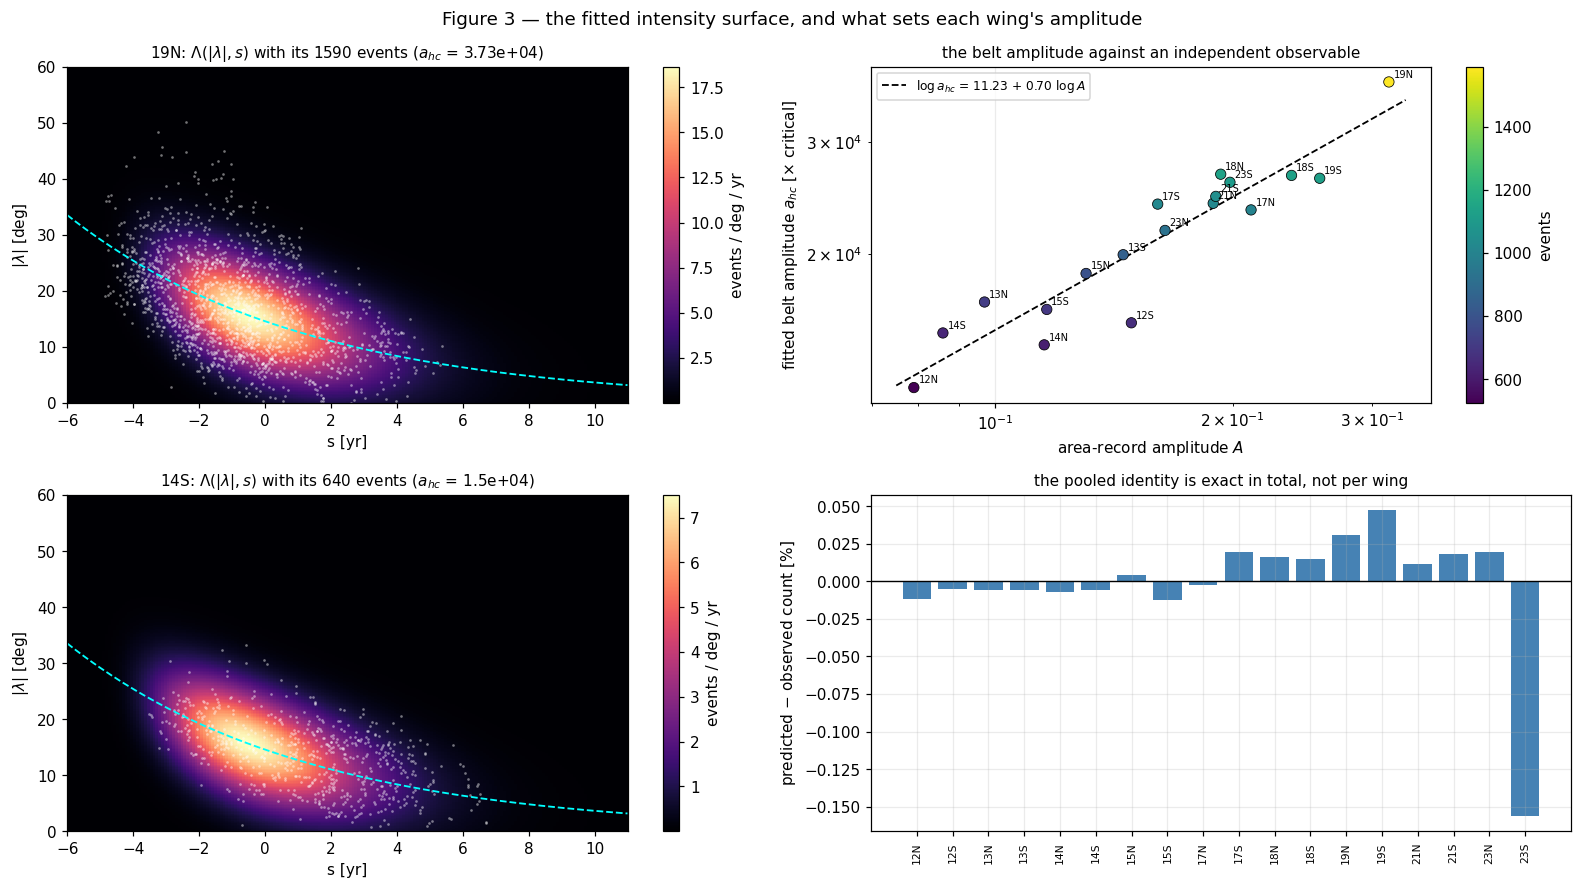

In [62]:
# Given: Figure 3 — the fitted intensity surface, and where the belt amplitude comes from.
fig = plt.figure(figsize=(14.5, 8.2))
show = ["19N", "14S"]

for row, label in enumerate(show):
    a_hc = POOLED["amplitudes"][label]
    surface = make_intensity(a_hc, shared)(LAM_2D[:, None], S_2D[None, :])
    lat_obs, s_obs = EVENTS[label]

    ax = fig.add_subplot(2, 2, 2 * row + 1)
    mesh_plot = ax.pcolormesh(S_2D, LAM_2D, surface, cmap="magma", shading="auto")
    ax.scatter(s_obs, lat_obs, s=3.0, c="white", alpha=0.45, linewidths=0)
    ax.plot(S_2D, drift(S_2D, shared["mu_a"], shared["mu_b"]), color="cyan", lw=1.2, ls="--")
    ax.set_xlim(S_A, S_B)
    ax.set_ylim(0, LAM_MAX)
    ax.set_xlabel("s [yr]")
    ax.set_ylabel(r"$|\lambda|$ [deg]")
    ax.set_title(f"{label}: $\\Lambda(|\\lambda|, s)$ with its {COUNTS[label]} events "
                 f"($a_{{hc}}$ = {a_hc:.3g})", fontsize=10)
    ax.grid(False)
    plt.colorbar(mesh_plot, ax=ax, label="events / deg / yr")

ax = fig.add_subplot(2, 2, 2)
ax.scatter(counts["A"], counts["a_hc"], s=46, c=counts["observed"], cmap="viridis",
           edgecolors="k", linewidths=0.5, zorder=3)
a_line = np.linspace(counts["A"].min() * 0.95, counts["A"].max() * 1.05, 20)
ax.plot(a_line, np.exp(np.polyval(log_fit, np.log(a_line))), "k--", lw=1.2,
        label=f"$\\log a_{{hc}}$ = {AMPLITUDE_MAP[0]:.2f} + {AMPLITUDE_MAP[1]:.2f} $\\log A$")
for label, row in counts.iterrows():
    ax.annotate(label, (row["A"], row["a_hc"]), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("area-record amplitude $A$")
ax.set_ylabel(r"fitted belt amplitude $a_{hc}$ [$\times$ critical]")
ax.set_title("the belt amplitude against an independent observable", fontsize=10)
ax.legend(fontsize=8)
plt.colorbar(ax.collections[0], ax=ax, label="events")

ax = fig.add_subplot(2, 2, 4)
ax.bar(np.arange(len(counts)), counts["error %"], color="steelblue")
ax.axhline(0.0, color="k", lw=0.9)
ax.set_xticks(np.arange(len(counts)))
ax.set_xticklabels(counts.index, rotation=90, fontsize=7)
ax.set_ylabel("predicted $-$ observed count [%]")
ax.set_title("the pooled identity is exact in total, not per wing", fontsize=10)
fig.suptitle("Figure 3 — the fitted intensity surface, and what sets each wing's amplitude")
plt.tight_layout()
plt.show()

### Dialogue for Section 5 — pooling, and what "held out" has to mean

Nothing to write here. Work this with your tutor before you implement Tasks 25 to 28 — it covers
Sections 5, 6 and 7 together, because they are one argument.

```text
TUTOR DIRECTIVE — Sections 5 to 7. Work this before the student implements Tasks 25 to 28.

Material: the student is about to fit one shape to all 18 development hemicycles with one amplitude each;
then generate synthetic wings from the fitted model by thinning and refit those to check the fitter; then
hold out an entire cycle, both hemispheres, and score it. None of it has been run. Section 2's clock has
been fitted and the student has seen that its per-hemicycle shifts carry about 0.1 yr of uncertainty.

Work this predictively. Name destinations, never outcomes.

1. Pooling. At the end of Week 02 the student took a position on what sharing a shape parameter across
   all 18 wings would buy and what it would cost; their HANDOFF should record it. Hold them to that
   position and ask them to make it quantitative now: which parameters should be shared, which must stay
   per-wing, and what rule they used to decide. Require them to name the quantity that pooling improves
   (data per parameter), and to say what observation would tell them the pooling assumption is wrong.
2. Whole cycles, not hemispheres. Ask why the held-out unit is an entire cycle, both hemispheres at once,
   rather than one wing while the model trains on the other. Push until they produce a mechanism by which
   the opposite hemisphere carries information about the held-out one.
3. The leak, which is this week's sharpest distinction and should take the longest. First: ask what is
   wrong with taking the held-out hemicycle's time origin from ButterflAI 1.0's fitted epochs. They
   should get there. Then the harder half: the notebook fits the held-out hemicycle's own origin from the
   held-out hemicycle's own events. Ask whether *that* is a leak, and do not answer it for them. Require
   them to decide, and then to state what kind of claim a score computed that way supports and what kind
   it does not. If they stall, bridge by asking what would change if the model were asked to predict a
   cycle that had not happened yet.
4. The amplitude. The held-out wing's belt strength has to come from somewhere: fitted from its own
   events, or predicted from the sunspot-area record, which is an independent observable. Require the
   student to argue both sides before any number exists, and to say which one they would put on a
   scoreboard and why. Ask what it would mean if the two scored almost the same, and what it would mean
   if the area-record version scored much worse.
5. Simulation as verification. Ask what can be checked about a model that *generates* data that cannot be
   checked about a curve fitted through data. Their Week 02 HANDOFF has the simulate-and-recover argument
   in it; hold them to it rather than re-deriving it, and require the extra step: what would a synthetic
   butterfly diagram have to look like for them to believe the fit, and what would close agreement still
   not establish?
6. Reading a held-out table. Before they see it: the per-hemicycle scores will differ from each other by
   far more than any two models will differ from each other. Ask them to predict what drives the
   hemicycle-to-hemicycle spread, and then — given that — how two models should be compared. Require them
   to arrive at a comparison that is immune to the spread. Do not use the word "paired".

`partial pooling`, `leave-one-cycle-out cross-validation` and `held-out log-likelihood` are the targets
least likely to have been deployed by this point; prefer them when you choose an anchor.
```

---
## 6 · Verify it: generate a wing

There is one new machine in this notebook — the pooled fitter — and nothing has checked that it works.
Week 2 established the habit that fixes this: before trusting a fitter on real data, make data whose
answer you already know, fit it, and see whether the answer comes back.

Week 2 did that by *thinning*: simulate a constant-rate process at some λ_max that bounds the model
everywhere, then keep each proposed event with probability λ/λ_max. The survivors are a realization of the
model. Nothing about that argument cares how many dimensions the domain has, so the same three lines work
here with latitude alongside time — propose uniformly over the whole rectangle, keep with probability
Λ/Λ_max.

The bound is exact and worth deriving rather than guessing. `B` is largest where `g(s)` peaks and where
`|λ|` sits exactly on the drift track, and `g` is normalized to peak 1, so `max B = a_hc` and

```
Lambda_max = c * softplus(a_hc - B_crit)^alpha
```

— no search, and the same expression whatever the belt width does, because at the centre of the band the
Gaussian equals 1 regardless of its width.

This also buys the thing ButterflAI 1.0 could not do at all. 1.0 modelled the latitude distribution as a
density: given that a group emerged, it said where. It could not say *how many* groups a cycle produces,
so it could not generate a butterfly diagram. An intensity can. By the end of this section we will have
made one.

In [ ]:
raise NotImplementedError("Task 27: Generate a synthetic wing by thinning, in two dimensions")
# Reference workflow:
#   1. Write `intensity_max(a_hc, shared)` from the formula in the text above. It is one line and needs no
#      search over the mesh — but do check it against the mesh maximum once, in the next cell.
#   2. In `simulate_wing`, draw the number of proposals from a Poisson distribution whose mean is
#      `rate_max` times the *area* of the domain in degree-years, then place each proposal uniformly in
#      latitude and uniformly in time. This is Week 2's constant-rate simulator with a second coordinate.
#   3. Compute each proposal's acceptance probability as the intensity there divided by `rate_max`, and
#      raise if any exceeds 1 — a bound that does not bound makes the simulation silently biased, which is
#      worse than an error.
#   4. Draw one uniform per proposal, keep those below their acceptance probability, and return the kept
#      latitudes and times plus the full proposal set and the mask.
#   Name them `intensity_max(a_hc, shared)` and `simulate_wing(intensity_fn, rate_max, rng, mesh=MESH_2D)`,
#   returning `(kept_lat, kept_s, proposed, keep_mask)` in that order.

In [63]:
def intensity_max(a_hc, shared):
    """Compute the exact maximum intensity over the entire lat-time domain.

    Since the Gaussian spatial factor equals 1.0 when |lat| is exactly on the drift track,
    and the normalized time profile peaks at 1.0, the maximum field strength B is exactly a_hc.
    """
    return shared["c"] * (softplus(a_hc - B_CRIT) ** ALPHA)


def simulate_wing(intensity_fn, rate_max, rng, mesh=MESH_2D):
    """Generate a synthetic wing's events by 2D thinning."""
    s_mesh, lam_mesh = mesh
    s_min, s_max = s_mesh.min(), s_mesh.max()
    lam_min, lam_max = lam_mesh.min(), lam_mesh.max()

    # Area of the bounding box
    domain_area = (s_max - s_min) * (lam_max - lam_min)
    expected_proposals = rate_max * domain_area

    # Draw the number of candidate events from a Poisson distribution
    n_proposals = rng.poisson(expected_proposals)

    # Place proposed events uniformly in both directions
    proposed_s = rng.uniform(s_min, s_max, n_proposals)
    proposed_lat = rng.uniform(lam_min, lam_max, n_proposals)
    proposed = np.column_stack((proposed_lat, proposed_s))

    # Compute acceptance probability for each proposal
    intensities = intensity_fn(proposed_lat, proposed_s)

    # Safety check to avoid any bias due to under-bounding
    if np.any(intensities > rate_max + 1e-9):
        raise ValueError("rate_max is not a valid bound! Maximum intensity exceeds rate_max.")

    keep_prob = intensities / rate_max
    keep_mask = rng.uniform(0.0, 1.0, n_proposals) < keep_prob

    return proposed_lat[keep_mask], proposed_s[keep_mask], proposed, keep_mask

In [64]:
# Given: check the analytic bound against the mesh, then simulate one synthetic wing per hemicycle.
for label in ("19N", "14S"):
    a_hc = POOLED["amplitudes"][label]
    on_mesh = make_intensity(a_hc, shared)(LAM_2D[:, None], S_2D[None, :]).max()
    print(f"{label}: analytic bound {intensity_max(a_hc, shared):.4f}  >=  "
          f"mesh maximum {on_mesh:.4f}   events / deg / yr")
    assert intensity_max(a_hc, shared) >= on_mesh - 1e-9

rng = np.random.default_rng(SEED + 300)
SYNTHETIC = {}
for label in DEV_HEMICYCLES:
    a_hc = POOLED["amplitudes"][label]
    lat_sim, s_sim, _, keep = simulate_wing(make_intensity(a_hc, shared),
                                            intensity_max(a_hc, shared), rng)
    SYNTHETIC[label] = (lat_sim, s_sim)

n_synthetic = sum(len(v[0]) for v in SYNTHETIC.values())
print(f"\nsynthetic development set: {n_synthetic:,} events against {len(dev):,} real ones "
      f"({100 * (n_synthetic / len(dev) - 1):+.1f}%)")
print(f"acceptance on the last wing: {100 * keep.mean():.1f}% of proposals kept")

19N: analytic bound 18.6498  >=  mesh maximum 18.6467   events / deg / yr
14S: analytic bound 7.5053  >=  mesh maximum 7.5040   events / deg / yr

synthetic development set: 16,809 events against 16,611 real ones (+1.2%)
acceptance on the last wing: 8.5% of proposals kept


In [65]:
# Given: refit the pooled model to the synthetic set, and compare against the parameters that generated it.
# The tolerance is the replicate-to-replicate spread, not a number of decimal places — each synthetic set
# is one random realization, so the estimates *should* scatter.
RECOVERED = fit_pooled(SYNTHETIC, DEV_HEMICYCLES, start=POOLED["q"],
                       amplitude_start=POOLED["amplitudes"], sweeps=3)

recovery_rows = []
for name in ("k", "theta", "mu_a", "mu_b"):
    recovery_rows.append(dict(parameter=name, truth=shared[name], recovered=RECOVERED["shared"][name]))
recovery_rows.append(dict(parameter="w", truth=shared["width_params"][0],
                          recovered=RECOVERED["shared"]["width_params"][0]))
recovery_rows.append(dict(parameter="c", truth=shared["c"], recovered=RECOVERED["shared"]["c"]))
recovery = pd.DataFrame(recovery_rows).set_index("parameter")
recovery["ratio"] = recovery["recovered"] / recovery["truth"]

print(recovery.to_string(float_format=lambda v: f"{v:14.5g}"))
worst = (recovery["ratio"] - 1.0).abs().max()
print(f"\nlargest fractional error over the six shared parameters: {100 * worst:.2f}%")
assert worst < 0.10, "the pooled fitter does not recover the parameters it was given — fix it first"

amp_ratio = np.array([RECOVERED["amplitudes"][h] / POOLED["amplitudes"][h] for h in DEV_HEMICYCLES])
print(f"per-hemicycle amplitudes recovered to {100 * np.abs(amp_ratio - 1).mean():.1f}% on average, "
      f"worst {100 * np.abs(amp_ratio - 1).max():.1f}%")
print("The fitter works. Note what this does *not* establish: the synthetic data came from this model by")
print("construction, so this tests the implementation, not whether the Sun has a belt.")

                   truth      recovered          ratio
parameter                                             
k                 7.6845          7.757         1.0094
theta            0.82161        0.81204        0.98836
mu_a              14.571         14.594         1.0016
mu_b               7.203         7.2589         1.0078
w                 6.5017          6.546         1.0068
c             0.00050003     0.00049999        0.99992

largest fractional error over the six shared parameters: 1.16%
per-hemicycle amplitudes recovered to 2.3% on average, worst 6.0%
The fitter works. Note what this does *not* establish: the synthetic data came from this model by
construction, so this tests the implementation, not whether the Sun has a belt.


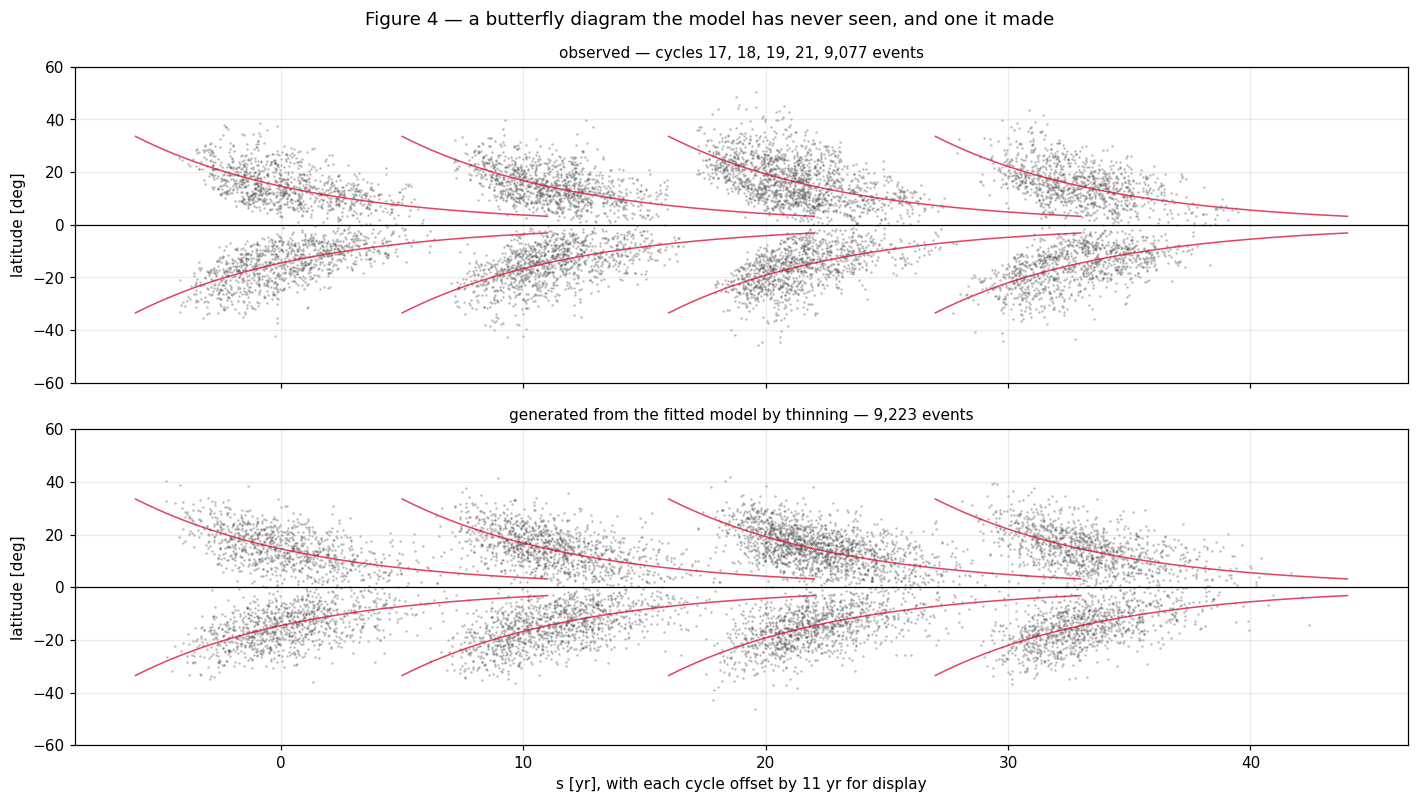

In [66]:
# Given: Figure 4 — the real butterfly diagram, and one the model made.
fig, axes = plt.subplots(2, 1, figsize=(13, 7.4), sharex=True, sharey=True)
SHOW_CYCLES = (17, 18, 19, 21)
offsets = {c: 11.0 * i for i, c in enumerate(SHOW_CYCLES)}


def draw_butterfly(ax, source, title):
    for cyc in SHOW_CYCLES:
        for hemi, sign in (("N", 1.0), ("S", -1.0)):
            label = f"{cyc}{hemi}"
            if label not in source:
                continue
            lat_here, s_here = source[label]
            ax.scatter(s_here + offsets[cyc], sign * lat_here, s=2.4, c="0.3", alpha=0.4, linewidths=0)
            track = drift(S_2D, shared["mu_a"], shared["mu_b"])
            ax.plot(S_2D + offsets[cyc], sign * track, color="crimson", lw=1.0, alpha=0.8)
    ax.axhline(0.0, color="k", lw=0.8)
    ax.set_ylim(-LAM_MAX, LAM_MAX)
    ax.set_ylabel("latitude [deg]")
    ax.set_title(title, fontsize=10)


draw_butterfly(axes[0], EVENTS, f"observed — cycles {', '.join(map(str, SHOW_CYCLES))}, "
                                f"{sum(COUNTS[f'{c}{h}'] for c in SHOW_CYCLES for h in 'NS'):,} events")
draw_butterfly(axes[1], SYNTHETIC, "generated from the fitted model by thinning — "
                                   f"{sum(len(SYNTHETIC[f'{c}{h}'][0]) for c in SHOW_CYCLES for h in 'NS'):,} events")
axes[1].set_xlabel("s [yr], with each cycle offset by 11 yr for display")
fig.suptitle("Figure 4 — a butterfly diagram the model has never seen, and one it made")
plt.tight_layout()
plt.show()

That is the figure to look at for a while, because it is the week's claim in one image: a model with six
shared numbers and one amplitude per wing, fitted to event times and latitudes by maximum likelihood,
generates something a solar physicist would accept as a butterfly diagram.

It is not perfect, and the imperfections are the honest content. Compare the two panels at the *start* of
each wing: the real wings begin at higher latitudes and more abruptly than the synthetic ones, because a
Gaussian band of fixed width with an exponential drift cannot be both narrow at high latitude and wide at
maximum. Section 8 takes that up. And compare the equatorward tails: the real ones thin out faster.

What this does *not* show is whether the model predicts a wing it was never fitted to. Figure 4 is
in-sample — every event in the top panel helped choose the parameters that made the bottom one.

---
## 7 · A held-out cycle

Everything so far has been scored on the data it was fitted to. Week 2 said so each time and promised this
week would fix it. The method is **leave-one-cycle-out cross-validation**: take one cycle out of the
development set, fit everything on the remaining eight, and score the cycle that was left out. Repeat for
all nine. The number that comes out is a **held-out log-likelihood** — the program's headline metric, in
nats per hemicycle-year.

*The unit removed is a whole cycle, both hemispheres together.* Not one wing while training on the other:
the two hemispheres of a cycle share the amplitude of the same global cycle, and from Week 5 the models
will use the opposite hemisphere directly, so withholding one hemisphere is not withholding anything.

Everything derived from data has to be re-derived inside each fold, and in this notebook that means three
things:

1. *The clock.* The shared drift timescale `mu_b` is refitted on the training hemicycles only. The
   held-out hemicycle's own shift is then fitted from its own events, with that timescale frozen. No
   information crosses between cycles, which is what leave-one-cycle-out protects.
2. *The shape.* The pooled fit runs on the training hemicycles only.
3. *The amplitude.* The held-out wing needs one, and this is the interesting choice. Either predict it
   from the sunspot-area record through the map fitted on the training wings — a genuine prediction, since
   the area record is an independent observable — or fit it from the held-out wing's own events, which is
   the best the shape could possibly do. We compute both. The first is the headline; the second is the
   bound, and the gap between them is what predicting the amplitude costs.

One honesty note that belongs wherever these numbers are quoted. The held-out wing contributes its own
time origin and, in the headline variant, nothing else. So the score measures how well the model predicts
the *shape* of a wing it has never seen, on a clock standardized from that wing's own events. It is not a
forecast of when a cycle will occur or how big it will be; that is a different problem, and this program
does not claim it.

In [ ]:
raise NotImplementedError("Task 28: Leave one cycle out, with the clock re-derived inside the fold")
# Reference workflow:
#   1. Write `align_one`: Task 21's residual for a single hemicycle, with `mu_b` passed in rather than
#      fitted, and one parameter to find. It must touch no events but that hemicycle's own.
#   2. Loop over the cycles. For each, build the list of training hemicycles — every hemicycle of every
#      *other* cycle — and refit the alignment on those, then express the training events in `s`.
#   3. Fit the pooled model on the training hemicycles with Task 26, and fit the amplitude map (a straight
#      line of log amplitude on log area amplitude) on the training hemicycles only.
#   4. For each held-out hemicycle: fit its own shift with `align_one`, convert its events to `s`, keep the
#      events inside the window, then score it twice — once with the amplitude predicted by the map, once
#      with the amplitude fitted from its own events. Record the score as a negative log-likelihood divided
#      by the window length, plus the predicted count each way.
#   Name them `align_one(event_t, abs_lat, t0_start, mu_b)` and
#   `leave_one_cycle_out(raw_events, cycles, t0_start, area_amplitude, start=None, sweeps=2,
#   width_fn=width_constant, n_width=1, width_start=(6.5,), mesh=MESH_2D, verbose=True)`, returning a
#   DataFrame indexed by hemicycle.

In [67]:
def align_one(event_t, abs_lat, t0_start, mu_b):
    """Fit a single hemicycle's time shift (delta) with a fixed shared timescale mu_b."""
    def residuals(delta):
        # For each event in this hemicycle: s = t - t0_start - delta
        s = event_t - t0_start - delta[0]
        mu_pred = MU_REF * np.exp(-s / mu_b)
        return mu_pred - abs_lat

    # Optimize single shift
    res = least_squares(residuals, [0.0], method="lm", xtol=1e-11, ftol=1e-11, gtol=1e-11)
    return float(res.x[0])


def leave_one_cycle_out(raw_events, cycles, t0_start, area_amplitude, start=None, sweeps=2,
                        width_fn=width_constant, n_width=1, width_start=(6.5,), mesh=MESH_2D, verbose=True):
    """Perform Leave-One-Cycle-Out (LOCO) cross-validation."""
    s_mesh, lam_mesh = mesh
    results = []

    # We loop over each development cycle to hold it out
    for held_out_cycle in sorted(cycles.keys()):
        if verbose:
            print(f"LOCO Fold: holding out cycle {held_out_cycle}...")

        # 1. Split into training and validation sets
        train_labels = [h for cyc, hs in cycles.items() if cyc != held_out_cycle for h in hs]
        val_labels = cycles[held_out_cycle]

        # 2. Re-fit alignment on the training folds
        train_unit_index = []
        train_event_t = []
        train_abs_lat = []
        for u_idx, h in enumerate(train_labels):
            lats, ts = raw_events[h]
            train_event_t.append(ts)
            train_abs_lat.append(lats)
            train_unit_index.append(np.full(len(ts), u_idx))

        train_unit_index = np.concatenate(train_unit_index)
        train_event_t = np.concatenate(train_event_t)
        train_abs_lat = np.concatenate(train_abs_lat)
        train_t0_start = np.array([t0_start[h] for h in train_labels])

        alignment = fit_alignment(train_event_t, train_abs_lat, train_unit_index, train_t0_start)
        mu_b_fold = alignment["mu_b"]

        # 3. Apply standard aligned clock on training events
        train_events_s = {}
        for j, h in enumerate(train_labels):
            lats, ts = raw_events[h]
            t0_hc = train_t0_start[j] + alignment["delta"][j]
            train_events_s[h] = (lats, ts - t0_hc)

        # 4. Fit the pooled model on training hemicycles
        pooled_fold = fit_pooled(train_events_s, train_labels, start=start, sweeps=sweeps,
                                 width_fn=width_fn, n_width=n_width, width_start=width_start, mesh=mesh)
        shared_fold = pooled_fold["shared"]

        # 5. Fit the amplitude map on training hemicycles only
        train_A = np.array([area_amplitude[h] for h in train_labels])
        train_a_hc = np.array([pooled_fold["amplitudes"][h] for h in train_labels])
        log_fit_fold = np.polyfit(np.log(train_A), np.log(train_a_hc), 1)

        # 6. Evaluate on validation hemicycles
        for h in val_labels:
            lat_val, t_val = raw_events[h]
            # Fit this validation hemicycle's clock shift using train timescale
            delta_val = align_one(t_val, lat_val, t0_start[h], mu_b_fold)
            s_val = t_val - (t0_start[h] + delta_val)

            # Retain only events inside the standardized observation window
            keep = (s_val > S_A) & (s_val < S_B)
            lat_val_win = lat_val[keep]
            s_val_win = s_val[keep]
            outside_count = len(s_val) - len(s_val_win)

            # Predict amplitude using the training map
            val_A = area_amplitude[h]
            a_hc_pred = float(np.exp(np.polyval(log_fit_fold, np.log(val_A))))

            # Fit amplitude directly from the wing's own validation events
            temp_shared = shared_fold.copy()
            temp_shared["c"] = 1.0  # temporary scale reset for fitting local amplitude

            # Temporarily solve scale factor on training set with c=1
            n_train_events = len(train_event_t)
            total_train_integrated = 0.0
            for th in train_labels:
                intensity_fn = make_intensity(pooled_fold["amplitudes"][th], temp_shared)
                grid_vals = intensity_fn(lam_mesh[:, None], s_mesh[None, :])
                total_train_integrated += integrate_2d(grid_vals, mesh)
            c_fold = n_train_events / total_train_integrated
            shared_fold_c = shared_fold.copy()
            shared_fold_c["c"] = c_fold

            a_hc_own = fit_hemicycle_amplitude(lat_val_win, s_val_win, shared_fold_c, mesh=mesh)

            # Calculate scores
            nll_area = -log_likelihood_2d(lat_val_win, s_val_win, make_intensity(a_hc_pred, shared_fold_c), mesh=mesh)
            nll_own = -log_likelihood_2d(lat_val_win, s_val_win, make_intensity(a_hc_own, shared_fold_c), mesh=mesh)

            # Calculate predicted counts
            pred_area_intensity = make_intensity(a_hc_pred, shared_fold_c)
            pred_area_grid = pred_area_intensity(lam_mesh[:, None], s_mesh[None, :])
            pred_count_area = integrate_2d(pred_area_grid, mesh)

            pred_own_intensity = make_intensity(a_hc_own, shared_fold_c)
            pred_own_grid = pred_own_intensity(lam_mesh[:, None], s_mesh[None, :])
            pred_count_own = integrate_2d(pred_own_grid, mesh)

            results.append({
                "hemicycle": h,
                "n": len(s_val_win),
                "outside": outside_count,
                "delta": delta_val,
                "a (area record)": a_hc_pred,
                "a (own events)": a_hc_own,
                "nll/yr (area record)": nll_area / WINDOW_YEARS,
                "nll/yr (own events)": nll_own / WINDOW_YEARS,
                "predicted (area record)": pred_count_area,
                "predicted (own events)": pred_count_own
            })

    return pd.DataFrame(results).set_index("hemicycle")

In [68]:
# Given: run the nine folds, with a cache. About 40 seconds the first time.
RAW_EVENTS = {h: (g["abs_latitude"].to_numpy(), g["t"].to_numpy()) for h, g in dev.groupby("hemicycle")}
CYCLE_UNITS = {c: [h for h in DEV_HEMICYCLES if int(h[:-1]) == c] for c in DEV_CYCLES}

LOCO_CACHE = DERIVED / "week03_loco_constant_w.csv"
if LOCO_CACHE.exists():
    loco_scores = pd.read_csv(LOCO_CACHE, index_col=0)
    print(f"loaded cached scores from {LOCO_CACHE.name}")
else:
    loco_scores = leave_one_cycle_out(RAW_EVENTS, CYCLE_UNITS, T0_START, AREA_AMPLITUDE,
                                      start=POOLED["q"], sweeps=2)
    loco_scores.to_csv(LOCO_CACHE)

loco_scores = loco_scores.loc[DEV_HEMICYCLES]
assert loco_scores["outside"].sum() == 0, "a held-out event fell outside the window after re-alignment"

print()
print(loco_scores[["n", "delta", "nll/yr (area record)", "nll/yr (own events)",
                   "predicted (area record)"]].to_string(float_format=lambda v: f"{v:12.3f}"))

in_sample = POOLED["nll"] / (len(DEV_HEMICYCLES) * WINDOW_YEARS)
print(f"\nin sample                        : {in_sample:8.3f} nats per hemicycle-year")
for source in ("area record", "own events"):
    column = loco_scores[f"nll/yr ({source})"]
    print(f"held out, amplitude from {source:12s}: {column.mean():8.3f} "
      f"(spread across hemicycles {column.std(ddof=1):.3f})")

LOCO Fold: holding out cycle 12...
LOCO Fold: holding out cycle 13...
LOCO Fold: holding out cycle 14...
LOCO Fold: holding out cycle 15...
LOCO Fold: holding out cycle 17...
LOCO Fold: holding out cycle 18...
LOCO Fold: holding out cycle 19...
LOCO Fold: holding out cycle 21...
LOCO Fold: holding out cycle 23...

              n        delta  nll/yr (area record)  nll/yr (own events)  predicted (area record)
hemicycle                                                                                       
12N         525        0.137                -2.065               -2.177                  570.917
12S         664       -0.137                -3.412               -4.999                  871.617
13N         716        0.317               -10.104              -10.541                  617.706
13S         850        0.168               -18.819              -18.834                  828.861
14N         613        0.050                -0.931               -1.391                  716.145
14S  

Now look at that spread before reading anything else into the means. The per-hemicycle held-out scores
run from about −0.3 to about −56 nats per hemicycle-year, with a standard deviation around 18. The
differences between the models in this notebook are between 0.1 and 3 nats. *A mean over hemicycles cannot
resolve them.*

The spread is not model error. It is the event count: the first term of the log-likelihood is a sum over
events, so a wing with 1,590 events lands an order of magnitude further from zero than one with 525. It
tells us almost nothing about how good the model is, and it swamps everything that does.

The comparison that works is *paired*: difference two models on the *same* wing, and look at the
distribution of those eighteen differences. The count cancels, because it is the same count on both sides.
This is the only way the rest of this notebook compares anything, and it is the reason a bare mean is not
a result in this program.

In [69]:
# Given: the paired comparison, applied to the question of where a held-out amplitude comes from.
paired = loco_scores["nll/yr (area record)"] - loco_scores["nll/yr (own events)"]
standard_error = paired.std(ddof=1) / np.sqrt(len(paired))

print("predicting the held-out amplitude from the area record, instead of fitting it from the wing itself:")
print(f"   paired difference : {paired.mean():+.3f} nats per hemicycle-year "
      f"(+ is worse)")
print(f"   spread of the differences : {paired.std(ddof=1):.3f}, standard error {standard_error:.3f}")
print(f"   so the cost is {abs(paired.mean()) / standard_error:.1f} standard errors — real, and small")
print(f"\nUnpaired, the same comparison would be {loco_scores['nll/yr (area record)'].mean():.2f} against "
      f"{loco_scores['nll/yr (own events)'].mean():.2f}")
print(f"with a hemicycle-to-hemicycle spread of {loco_scores['nll/yr (area record)'].std(ddof=1):.1f}: "
      f"invisible.")

predicting the held-out amplitude from the area record, instead of fitting it from the wing itself:
   paired difference : +0.279 nats per hemicycle-year (+ is worse)
   spread of the differences : 0.376, standard error 0.089
   so the cost is 3.2 standard errors — real, and small

Unpaired, the same comparison would be -25.39 against -25.67
with a hemicycle-to-hemicycle spread of 18.1: invisible.


In [70]:
# Given: the physical-plausibility check. Does the held-out prediction get the wing's count and its
# latitude distribution right? None of these quantities is the likelihood, so none is guaranteed.
plausibility = pd.DataFrame(index=DEV_HEMICYCLES)
plausibility["observed"] = pd.Series(COUNTS)
plausibility["predicted"] = loco_scores["predicted (area record)"]
plausibility["count error %"] = 100 * (plausibility["predicted"] - plausibility["observed"]) / plausibility["observed"]
observed_centroid, observed_spread, model_centroid, model_spread = {}, {}, {}, {}
for label in DEV_HEMICYCLES:
    lat_obs, _ = EVENTS[label]
    observed_centroid[label] = float(np.mean(lat_obs))
    observed_spread[label] = float(np.std(lat_obs, ddof=1))
    a_hc = loco_scores.loc[label, "a (area record)"]
    surface = make_intensity(a_hc, shared)(LAM_2D[:, None], S_2D[None, :])
    weight = trapezoid(surface, S_2D, axis=1)
    total = trapezoid(weight, LAM_2D)
    mean_lat = trapezoid(weight * LAM_2D, LAM_2D) / total
    model_centroid[label] = float(mean_lat)
    model_spread[label] = float(np.sqrt(trapezoid(weight * (LAM_2D - mean_lat) ** 2, LAM_2D) / total))
plausibility["centroid obs"] = pd.Series(observed_centroid)
plausibility["centroid model"] = pd.Series(model_centroid)
plausibility["spread obs"] = pd.Series(observed_spread)
plausibility["spread model"] = pd.Series(model_spread)

print(plausibility.to_string(float_format=lambda v: f"{v:11.2f}"))
print(f"\ncount error, held out      : {plausibility['count error %'].abs().mean():.1f}% on average, "
      f"worst {plausibility['count error %'].abs().max():.1f}%")
print(f"latitude centroid           : model {plausibility['centroid model'].mean():.2f} deg vs "
      f"observed {plausibility['centroid obs'].mean():.2f} deg")
print(f"latitude spread             : model {plausibility['spread model'].mean():.2f} deg vs "
      f"observed {plausibility['spread obs'].mean():.2f} deg")
print(f"\nLook down the two model columns: they are the *same number for every hemicycle*, while the")
print(f"observed centroid runs {plausibility['centroid obs'].min():.1f} to "
      f"{plausibility['centroid obs'].max():.1f} deg and the observed spread "
      f"{plausibility['spread obs'].min():.1f} to {plausibility['spread obs'].max():.1f} deg.")
print("That is not a bug, it is what this model says. Far above critical the threshold stops biting, so")
print("the intensity is the belt shape multiplied by an amplitude — and multiplying a distribution by a")
print("constant does not move its centroid or its width. A constant-width belt therefore predicts one")
print("latitude distribution for every wing in the development set, and the data plainly has eighteen.")
print("Section 8 is about closing that gap, and this table is the reason it exists.")

     observed   predicted  count error %  centroid obs  centroid model  spread obs  spread model
12N       525      570.92           8.75         14.09           15.14        6.25          7.24
12S       664      871.62          31.27         13.54           15.14        6.34          7.24
13N       716      617.71         -13.73         14.12           15.14        6.37          7.24
13S       850      828.86          -2.49         14.62           15.14        6.59          7.24
14N       613      716.14          16.83         12.68           15.14        5.64          7.24
14S       640      582.24          -9.03         13.52           15.14        6.14          7.24
15N       794      778.86          -1.91         13.52           15.14        6.47          7.24
15S       697      719.26           3.19         14.91           15.14        6.20          7.24
17N      1000     1088.22           8.82         15.09           15.14        7.01          7.24
17S      1021      897.90     

In [71]:
# Given: the one comparison that *can* cross between the 1D and 2D models. The time-rescaling KS statistic
# is dimensionless, so it does not care that the two log-likelihoods are scores on different quantities.
# The 2D model's time marginal is its latitude integral, built on Week 2's frozen 4001-node time axis so
# that the compensator is never limited by the coarser fitting mesh.
def time_marginal(a_hc, shared, s_values=S_MESH, lam_mesh=LAM_2D):
    """lambda(s) = integral over latitude of Lambda(|lat|, s): events per year."""
    surface = make_intensity(a_hc, shared)(lam_mesh[:, None], np.asarray(s_values)[None, :])
    return trapezoid(surface, lam_mesh, axis=0)


GAMMA_FITS = {h: fit_hemicycle(np.sort(EVENTS[h][1])) for h in DEV_HEMICYCLES}

ks_rows = []
for j, label in enumerate(DEV_HEMICYCLES):
    event_s = np.sort(EVENTS[label][1])
    jitter = lambda: np.random.default_rng(SEED + 1000 + j)   # same draw for both models
    marginal = time_marginal(POOLED["amplitudes"][label], shared)
    belt_gaps = rescaled_gaps(event_s, lambda s: np.interp(s, S_MESH, marginal), rng=jitter())
    q_hat, s_first = GAMMA_FITS[label]
    gamma_gaps = rescaled_gaps(event_s, lambda s: gamma_rate(s, q_hat, s_first), rng=jitter())
    ks_rows.append(dict(hemicycle=label, n=len(event_s),
                        belt=ks_vs_exp1(belt_gaps), gamma=ks_vs_exp1(gamma_gaps),
                        belt_p=kstest(belt_gaps, "expon").pvalue,
                        gamma_p=kstest(gamma_gaps, "expon").pvalue))
ks_table = pd.DataFrame(ks_rows).set_index("hemicycle")

print(ks_table[["n", "belt", "gamma"]].to_string(float_format=lambda v: f"{v:10.4f}"))
print(f"\nmedian KS vs Exp(1): latent belt {ks_table['belt'].median():.4f} · "
      f"Week 2 direct rate {ks_table['gamma'].median():.4f}")
print(f"not rejected at 5%: belt {int((ks_table['belt_p'] > 0.05).sum())} of {len(ks_table)} · "
      f"direct rate {int((ks_table['gamma_p'] > 0.05).sum())} of {len(ks_table)}")
print("\nThe belt is the *worse* of the two on time alone, and that is exactly what pooling costs: Week 2")
print("spent four parameters per wing on the time shape, while the belt spends two shared across all 18")
print("plus one amplitude each. What it buys for that is a latitude distribution the direct rate does not")
print("have at all, eighteen times fewer parameters, and a model that can be handed a wing it never saw.")

              n       belt      gamma
hemicycle                            
12N         525     0.0437     0.0254
12S         664     0.0946     0.0462
13N         716     0.0303     0.0217
13S         850     0.0249     0.0156
14N         613     0.1301     0.0426
14S         640     0.1104     0.0781
15N         794     0.0644     0.0325
15S         697     0.0297     0.0330
17N        1000     0.0276     0.0261
17S        1021     0.0197     0.0244
18N        1138     0.0371     0.0303
18S        1133     0.0305     0.0233
19N        1590     0.0730     0.0209
19S        1121     0.0568     0.0251
21N        1024     0.0286     0.0219
21S        1050     0.0296     0.0290
23N         928     0.0242     0.0186
23S        1107     0.0368     0.0277

median KS vs Exp(1): latent belt 0.0337 · Week 2 direct rate 0.0258
not rejected at 5%: belt 12 of 18 · direct rate 17 of 18

The belt is the *worse* of the two on time alone, and that is exactly what pooling costs: Week 2
spent four param

In [ ]:
raise NotImplementedError("Task 29: Anti-gaming — what the headline score is sensitive to")
# Reference workflow:
#   1. Write `rescore(mesh, ...)`: evaluate the Task 24 log-likelihood of the *already fitted* model on a
#      given mesh, sum over hemicycles, and divide by the number of hemicycles times the time span of that
#      mesh. Nothing is refitted — the model's predictions are identical in every row.
#   2. Build the four variants above: the frozen mesh, the latitude domain stretched to 90 degrees, the time
#      window stretched to s = +15, and the mesh coarsened to 101 x 31 nodes.
#   3. Collect them into a DataFrame named `gaming` with a `score` column and a `moved by` column holding
#      the difference from the frozen mesh's score.
#   4. Before you run it: write down which of the three changes you expect to *improve* the score, and by
#      roughly how much. Commit to that prediction first — it is the whole point of the exercise.

In [72]:
def rescore(mesh, lat_max, s_start, s_end):
    """Evaluate the log-likelihood of the already fitted model on a given custom mesh and domain constraints."""
    s_mesh, lam_mesh = mesh
    # Re-scale time axis span for denominator if window size changed
    span = s_end - s_start

    total_ll = 0.0
    for h in DEV_HEMICYCLES:
        lat_obs, s_obs = EVENTS[h]
        # Keep events within the given window
        keep = (s_obs >= s_start) & (s_obs <= s_end) & (np.abs(lat_obs) <= lat_max)
        s_obs_win = s_obs[keep]
        lat_obs_win = lat_obs[keep]

        intensity_fn = make_intensity(POOLED["amplitudes"][h], shared)
        val = log_likelihood_2d(lat_obs_win, s_obs_win, intensity_fn, mesh=mesh)
        total_ll += val

    # Return normalized log-likelihood per hemicycle-year
    return total_ll / (len(DEV_HEMICYCLES) * span)

# Create gaming variants
gaming_results = {}

# 1. Baseline: Frozen Mesh & Domain
gaming_results["frozen mesh (baseline)"] = rescore(MESH_2D, LAM_MAX, S_A, S_B)

# 2. Stretch Latitude Domain to 90 degrees (with a 201 x 361 mesh to maintain 0.25 deg spacing)
mesh_lat90 = (S_2D, np.linspace(0.0, 90.0, 361))
gaming_results["latitude to 90 deg"] = rescore(mesh_lat90, 90.0, S_A, S_B)

# 3. Stretch Time Window to s = +15 (with a 248 x 241 mesh to maintain ~31 day spacing)
s_stretch = np.linspace(S_A, 15.0, 248)
mesh_s15 = (s_stretch, LAM_2D)
gaming_results["time window to +15 yr"] = rescore(mesh_s15, LAM_MAX, S_A, 15.0)

# 4. Coarsen Mesh to 101 x 31
mesh_coarse = MESH_CANDIDATES["101 x  31"]
gaming_results["coarse 101 x 31 mesh"] = rescore(mesh_coarse, LAM_MAX, S_A, S_B)

# Collect into gaming DataFrame
gaming = pd.DataFrame({
    "score": pd.Series(gaming_results)
})
gaming["moved by"] = gaming["score"] - gaming["score"].loc["frozen mesh (baseline)"]


In [73]:
# Given: the result, and what follows from it.
print(gaming.to_string(float_format=lambda v: f"{v:12.4f}"))
print("\nNot one of these rows changed a single prediction. The fitted model is identical in all four; only")
print("the ruler moved. The coarse mesh *improves* the score, through quadrature error alone, by about as")
print("much as the difference between two of this notebook's width models. Widening the window moves it by")
print("five nats in the other direction, purely through the denominator — the extra years contain no events")
print("and almost no predicted intensity, so the log-likelihood barely changes while the divisor grows.")
print("Either way the number means nothing unless the mesh, the domain and the window are all quoted with")
print("it, which is why all three are frozen rather than chosen per experiment.")

                              score     moved by
frozen mesh (baseline)      26.5954       0.0000
latitude to 90 deg          26.5907      -0.0047
time window to +15 yr       21.5195      -5.0759
coarse 101 x 31 mesh        26.6352       0.0398

Not one of these rows changed a single prediction. The fitted model is identical in all four; only
the ruler moved. The coarse mesh *improves* the score, through quadrature error alone, by about as
much as the difference between two of this notebook's width models. Widening the window moves it by
five nats in the other direction, purely through the denominator — the extra years contain no events
and almost no predicted intensity, so the log-likelihood barely changes while the divisor grows.
Either way the number means nothing unless the mesh, the domain and the window are all quoted with
it, which is why all three are frozen rather than chosen per experiment.


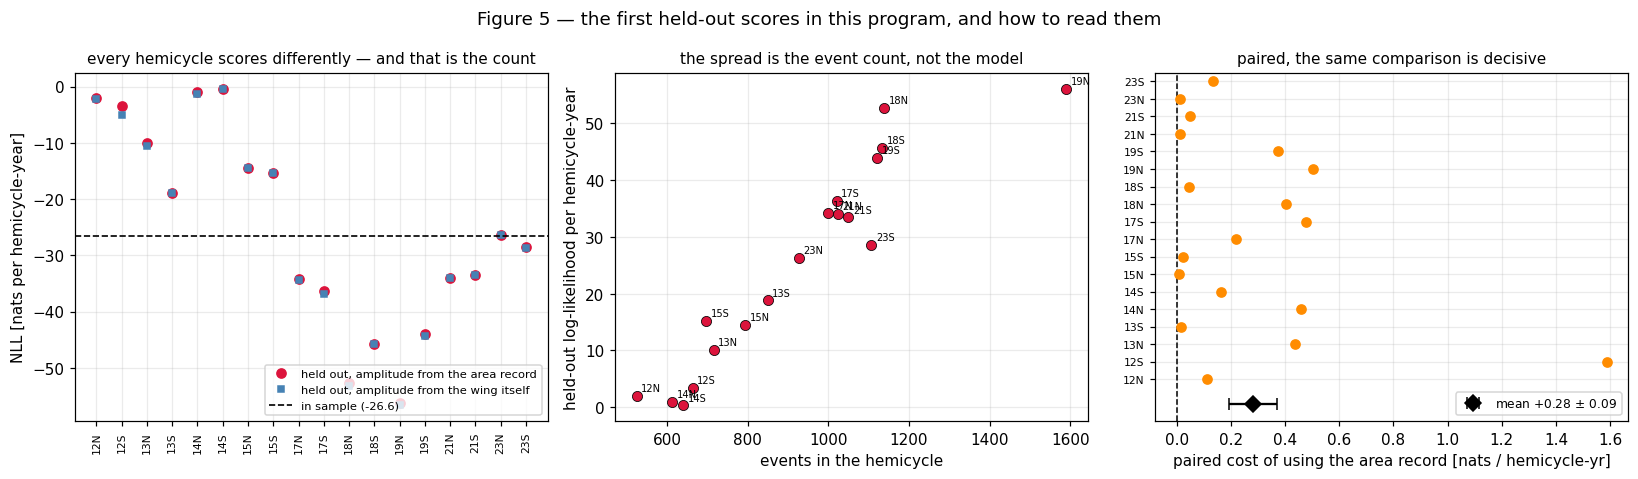

In [74]:
# Given: Figure 5 — the held-out result.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

ax = axes[0]
position = np.arange(len(loco_scores))
ax.plot(position, loco_scores["nll/yr (area record)"], "o", ms=6, color="crimson",
        label="held out, amplitude from the area record")
ax.plot(position, loco_scores["nll/yr (own events)"], "s", ms=4.5, color="steelblue",
        label="held out, amplitude from the wing itself")
ax.axhline(in_sample, color="k", lw=1.1, ls="--", label=f"in sample ({in_sample:.1f})")
ax.set_xticks(position)
ax.set_xticklabels(loco_scores.index, rotation=90, fontsize=7)
ax.set_ylabel("NLL [nats per hemicycle-year]")
ax.set_title("every hemicycle scores differently — and that is the count", fontsize=10)
ax.legend(fontsize=7.5, loc="lower right")

ax = axes[1]
ax.scatter(loco_scores["n"], -loco_scores["nll/yr (area record)"], s=44, color="crimson",
           edgecolors="k", linewidths=0.5, zorder=3)
for label, row in loco_scores.iterrows():
    ax.annotate(label, (row["n"], -row["nll/yr (area record)"]), fontsize=6.5,
                xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("events in the hemicycle")
ax.set_ylabel("held-out log-likelihood per hemicycle-year")
ax.set_title("the spread is the event count, not the model", fontsize=10)

ax = axes[2]
ax.axvline(0.0, color="k", lw=1.0, ls="--")
ax.plot(paired.to_numpy(), position, "o", ms=6, color="darkorange")
ax.errorbar([paired.mean()], [-1.4], xerr=[standard_error], fmt="D", ms=7, color="k",
            capsize=4, label=f"mean {paired.mean():+.2f} $\\pm$ {standard_error:.2f}")
ax.set_yticks(position)
ax.set_yticklabels(loco_scores.index, fontsize=7)
ax.set_ylim(-2.4, len(loco_scores) - 0.5)
ax.set_xlabel("paired cost of using the area record [nats / hemicycle-yr]")
ax.set_title("paired, the same comparison is decisive", fontsize=10)
ax.legend(fontsize=8, loc="lower right")
fig.suptitle("Figure 5 — the first held-out scores in this program, and how to read them")
plt.tight_layout()
plt.show()

---
## 8 · Does the belt's width vary — and with what?

Figure 4 showed the model's one obvious failure: the real wings start higher and more sharply than the
synthetic ones. A band of *fixed* latitudinal width cannot be narrow when the belt is at 30° and broad
when it is at 15°, and the data looks like it wants both.

ButterflAI 1.0 said the same thing in its own language. Its latitude spread was a function of the belt's
central latitude, σ(μ), rising on the equatorward side with a slope of about 0.45 — so 1.0's width ran
from roughly 2° near the equator to 7° at maximum, a factor of three across a wing. Our single `w` is an
average of that.

There are two different hypotheses here and they are easy to confuse:

- the belt is *wider in stronger cycles* — width depends on amplitude, `w(a_hc)`;
- the belt is *wider at higher latitude* — width depends on position, `w(μ)`, which is 1.0's claim.

They make different predictions and the data can tell them apart. One knob each, one question each, scored
the same way on the same folds.

In [ ]:
raise NotImplementedError("Task 30: Measure how the observed latitude spread scales with the number of events")
# Reference workflow:
#   1. For each hemicycle, take its events' |latitude| and the drift track evaluated at their times.
#   2. Record two different operational definitions of "the latitude spread": the standard deviation of the
#      *residual* about the drift track, and the standard deviation of the raw |latitude| values. They are
#      not the same quantity — the second includes the spread the drift itself produces over a wing — and
#      the model predicts the first.
#   3. Regress the log of each spread on the log of the event count across the 18 hemicycles, and keep the
#      two slopes. That slope is d log sigma / d log N.
#   Two names the next cells need: the table must be `width_scaling`, with columns `n`, `sigma_residual`
#   and `sigma_raw`, and the slopes must be in a dict `WIDTH_SLOPES` keyed by column name.

In [76]:
import numpy as np
import pandas as pd

# Prepare containers for Task 30 data
scaling_data = []

for h in DEV_HEMICYCLES:
    lat_obs, s_obs = EVENTS[h]  # raw |latitude| and aligned time s

    # 1. Operational definitions of latitudinal spread:
    # Raw |latitude| spread
    sigma_raw = np.std(lat_obs, ddof=1)

    # Residual about the drift track mu(s)
    mu_s = drift(s_obs, shared["mu_a"], shared["mu_b"])
    residual = lat_obs - mu_s
    sigma_residual = np.std(residual, ddof=1)

    scaling_data.append({
        "hemicycle": h,
        "n": len(lat_obs),
        "sigma_residual": float(sigma_residual),
        "sigma_raw": float(sigma_raw)
    })

width_scaling = pd.DataFrame(scaling_data).set_index("hemicycle")

# 2. Regress the log of each spread on the log of the event count
WIDTH_SLOPES = {}
for column in ["sigma_residual", "sigma_raw"]:
    slope, _ = np.polyfit(np.log(width_scaling["n"]), np.log(width_scaling[column]), 1)
    WIDTH_SLOPES[column] = float(slope)


In [77]:
# Given: the measurement.
print(width_scaling.to_string(float_format=lambda v: f"{v:12.3f}"))
for column, slope in WIDTH_SLOPES.items():
    r = np.corrcoef(np.log(width_scaling["n"]), np.log(width_scaling[column]))[0, 1]
    print(f"\n{column:16s}: d log sigma / d log N = {slope:+.3f}   (r = {r:+.3f})")
print("\nBoth definitions say the latitude spread grows with the number of events, which is the same thing")
print("as growing with amplitude. The two slopes differ by about 15%, which is a useful reminder that a")
print("scaling exponent is a property of a definition as much as of the Sun.")

              n  sigma_residual    sigma_raw
hemicycle                                   
12N         525           4.927        6.247
12S         664           5.387        6.344
13N         716           5.421        6.375
13S         850           5.812        6.588
14N         613           4.892        5.640
14S         640           5.236        6.137
15N         794           5.675        6.469
15S         697           5.125        6.201
17N        1000           6.086        7.014
17S        1021           5.866        7.404
18N        1138           5.981        6.695
18S        1133           6.515        7.519
19N        1590           7.489        8.507
19S        1121           6.475        7.605
21N        1024           6.526        7.434
21S        1050           6.445        7.556
23N         928           6.369        7.359
23S        1107           6.502        7.685

sigma_residual  : d log sigma / d log N = +0.388   (r = +0.950)

sigma_raw       : d log sigma / d 

In [ ]:
raise NotImplementedError("Task 31: Three width models, one knob each, scored held out")
# Reference workflow:
#   1. Write the two new width rules. Both take `(mu, a_hc, params)` so that they are interchangeable with
#      `width_constant` inside `make_intensity`. The amplitude rule is a power law in `a_hc` divided by a
#      reference amplitude; the latitude rule is linear in `mu` and must refuse to return a non-positive
#      width — return `nan` there and let the likelihood reject it.
#   2. Set `AMPLITUDE_REFERENCE` to the geometric mean of the fitted amplitudes, so that `w0` means the
#      width of a typical wing in all three models and the comparison is between like and like.
#   3. For each of the three models: fit it on all 18 hemicycles with Task 26, then run Task 28's
#      leave-one-cycle-out on it. The constant-width model is already done — Section 5 fitted it and
#      Section 7 scored it — so reuse those rather than repeating them. Cache each new fold table under
#      `DERIVED` and skip the work if the file is already there.
#   4. Collect the in-sample and held-out scores into `width_comparison`, with the fitted width parameters
#      beside them. Remember the sign convention: the table reports log-likelihood per hemicycle-year, so
#      *higher is better* — the opposite of the NLL columns.
#   Two names the next cells need: `width_results`, a dict keyed by model name with keys `fit` and `held`,
#   and `width_comparison`.

In [78]:
def width_amplitude(mu, a_hc, params):
    # params[0] is w0 (width at typical amplitude), params[1] is the scaling exponent
    w0, exponent = params
    return w0 * (a_hc / AMPLITUDE_REFERENCE) ** exponent

def width_latitude(mu, a_hc, params):
    # params[0] is w0 (width at equator), params[1] is w1 (slope with respect to mu)
    w0, w1 = params
    w = w0 + w1 * mu
    if np.any(w <= 0.0):
        return np.nan
    return w

# Geometric mean of the fitted amplitudes to serve as the reference typical amplitude
amps_array = np.array(list(POOLED["amplitudes"].values()))
AMPLITUDE_REFERENCE = float(np.exp(np.mean(np.log(amps_array))))
print(f"AMPLITUDE_REFERENCE = {AMPLITUDE_REFERENCE:.3f}")

# Set up specifications for the three models
WIDTH_MODELS = {
    "constant w": {
        "fn": width_constant,
        "n_params": 1,
        "start": (6.5,),
        "q_start": POOLED["q"]
    },
    "w(a_hc)": {
        "fn": width_amplitude,
        "n_params": 2,
        "start": (6.5, 0.5),
        "q_start": np.concatenate([POOLED["q"][:4], [np.log(6.5), 0.5]])
    },
    "w = w0 + w1 mu": {
        "fn": width_latitude,
        "n_params": 2,
        "start": (5.0, 0.1),
        "q_start": np.concatenate([POOLED["q"][:4], [np.log(5.0), 0.1]])
    }
}

AMPLITUDE_REFERENCE = 20841.290


In [ ]:
width_results = {}

# Populate "constant w" from the already computed fits
width_results["constant w"] = {
    "fit": POOLED,
    "held": loco_scores
}

# Process the other two models
for name in ["w(a_hc)", "w = w0 + w1 mu"]:
    spec = WIDTH_MODELS[name]
    print(f"Fitting {name} model...")

    # In-sample fit
    fit_res = fit_pooled(EVENTS, DEV_HEMICYCLES, start=spec["q_start"], sweeps=3,
                         width_fn=spec["fn"], n_width=spec["n_params"], width_start=spec["start"])

    # LOCO Cross-Validation
    cache_file = DERIVED / f"week03_loco_{name.replace(' ', '_').replace('=', '_').replace('(', '_').replace(')', '_')}.csv"
    if cache_file.exists():
        held_res = pd.read_csv(cache_file, index_col=0)
        print(f"Loaded LOCO cached results for {name}")
    else:
        held_res = leave_one_cycle_out(RAW_EVENTS, CYCLE_UNITS, T0_START, AREA_AMPLITUDE,
                                       start=spec["q_start"], sweeps=2, width_fn=spec["fn"],
                                       n_width=spec["n_params"], width_start=spec["start"], verbose=False)
        held_res.to_csv(cache_file)

    width_results[name] = {
        "fit": fit_res,
        "held": held_res.loc[DEV_HEMICYCLES]
    }

Fitting w(a_hc) model...
Fitting w = w0 + w1 mu model...


In [ ]:
# Build the comparison table
comparison_rows = []
for name in ["constant w", "w(a_hc)", "w = w0 + w1 mu"]:
    fit = width_results[name]["fit"]
    held = width_results[name]["held"]

    # Log-likelihood per hemicycle-year: higher is better
    in_sample_ll_yr = -fit["nll"] / (len(DEV_HEMICYCLES) * WINDOW_YEARS)
    held_out_ll_yr = held["nll/yr (area record)"].mean()

    # Extract physical width parameters
    w_params = fit["shared"]["width_params"]
    w0 = w_params[0]
    w1 = w_params[1] if len(w_params) > 1 else np.nan

    comparison_rows.append({
        "model": name,
        "w0": w0,
        "w1": w1,
        "in-sample [LL/yr]": in_sample_ll_yr,
        "held-out [LL/yr]": held_out_ll_yr
    })

width_comparison = pd.DataFrame(comparison_rows).set_index("model")

In [ ]:
# Given: the comparison, paired against the constant-width model on the same folds.
print(width_comparison.to_string(float_format=lambda v: f"{v:12.4f}"))

baseline = width_results["constant w"]["held"]["nll/yr (area record)"]
print("\npaired against constant w, hemicycle by hemicycle (negative = the variant is better):")
for name in ("w(a_hc)", "w = w0 + w1 mu"):
    difference = width_results[name]["held"]["nll/yr (area record)"] - baseline
    se = difference.std(ddof=1) / np.sqrt(len(difference))
    print(f"   {name:18s} mean {difference.mean():+7.3f} +/- {se:.3f}   "
          f"median {difference.median():+7.3f}   better in {int((difference < 0).sum())} of "
          f"{len(difference)}   most helped: {difference.idxmin()} ({difference.min():+.2f})")
print("\nThe mean and the median disagree, and that matters: look at the single most-helped hemicycle.")

latitude_width = width_results["w = w0 + w1 mu"]["fit"]["shared"]["width_params"]
print(f"\nthe latitude model fits w = {latitude_width[0]:.3f} + {latitude_width[1]:.4f} mu, so the belt is")
print(f"{latitude_width[0] + latitude_width[1] * 5:.2f} deg wide at mu = 5 deg and "
      f"{latitude_width[0] + latitude_width[1] * 30:.2f} deg at mu = 30 deg.")
print(f"1.0's sigma(mu) rose with slope {model_10.params.m_shared:.3f}; ours rises with "
      f"{latitude_width[1]:.3f} — the same sign, a quarter of the steepness.")

The answer is that the belt's width is *not* constant, and both hypotheses have something in them: both
variants beat the constant width held out, not just in sample. But the two results have very different
shapes, and reading them properly is the point of the section.

*The amplitude-dependent width wins by more on the mean, and almost all of the margin comes from one
wing.* Its mean paired gain is about 0.7 nats per hemicycle-year, its *median* only about 0.3, it is
better in 16 of 18 hemicycles — and 19N alone contributes about 5 nats. That is not a defect of the
comparison; it is the comparison telling us where the constant-width model is worst. Section 7's
plausibility table already said so: far above critical, the intensity is the belt shape times an
amplitude, and multiplying a distribution by a constant moves neither its centroid nor its width, so a
constant-width model predicts *one* latitude distribution for all 18 wings. 19N is the strongest wing and
the furthest from that single distribution — observed spread 8.5° against the model's 7.2° — so a width
that grows with amplitude is worth most exactly there. The fitted exponent is about 0.5, i.e. the belt
widens roughly as the square root of its field strength.

This is why a mean over eighteen units is not the end of the analysis even when it is paired. A skewed
distribution of paired differences and a mean driven by one unit is a real finding about *where* a model
fails, and quoting the mean alone would have hidden it. Report the mean, the median and the sign count.

*The latitude-dependent width wins by less and more evenly* — a median gain of about 0.08 nats per
hemicycle-year, better in 14 of 18. So 1.0's central shape result survives contact with a likelihood on
event times: the belt really is wider when it is further from the equator. It is just much flatter than
1.0 said, rising with about a quarter of 1.0's slope in `σ(μ)`.

And the data's `d log σ / d log N ≈ +0.34 to +0.39` turns out not to settle anything on its own. Spread
grows with event count — but *both* mechanisms produce that. A width that grows with amplitude does it
directly; a width that grows with latitude does it too, because the belt drifts equatorward and a stronger
cycle emerges over more of the range, so its wing averages in more of the wide high-latitude part. The
held-out comparison can separate the two explanations; a scaling exponent measured in the data cannot.

One thing worth noticing about the exercise as a whole: the in-sample ranking and the held-out ranking
happen to agree here. That is luck, not a rule, and it would have been a worse week for the students if
they had agreed by construction — which is why the amplitude variant was worth running even though it is
the one most exposed to error in a quantity that has to be guessed at prediction time.

### Dialogue for Section 8 — a scaling, and where it comes from

Nothing to write here. Work this with your tutor before you implement Tasks 30 and 31.

```text
TUTOR DIRECTIVE — Section 8. Work this before the student implements Tasks 30 and 31.

Material: the student is about to measure how the observed latitudinal spread of emergence scales with
the number of events in a hemicycle, and then to compare three models of the belt width — constant, a
power law in the hemicycle's amplitude, and linear in the belt's own latitude — by fitting each and
scoring it on held-out cycles. None of it has been run. They have seen Figure 4, where the synthetic
wings start lower and less sharply than the real ones.

Work this predictively, and do not state any of the outcomes.

1. Before any measurement: require a prediction of the sign of d log sigma / d log N, with a reason. Then
   ask them to give two different operational definitions of "the latitudinal spread of a wing" and to
   say which one the belt width in the model corresponds to. Do not accept one definition.
2. The mechanism, worked without fitting anything. A belt of fixed width sits above the threshold only
   where its field exceeds critical. Ask what happens to the *width of the emitting region* as the
   amplitude rises with the belt width held fixed, and then what that implies for how the observed spread
   should scale with amplitude. Require the argument, not a number. If they stall, bridge by asking where
   on a Gaussian the threshold cuts when the peak is twice critical versus a hundred times critical.
3. Now separate the two hypotheses, which is the section's real work: wider in stronger cycles, versus
   wider at higher latitude. Both produce a positive correlation between spread and event count. Require
   the student to explain why the second one does, before they see any fit — the belt drifts equatorward,
   so ask what a wing's spread is averaging over. Then ask what measurement could distinguish them, and
   hold out for an answer that is not "fit both and see which likelihood is higher".
4. In-sample and held-out. Tell them one variant will gain a large in-sample margin, and ask what could
   make a model that fits better predict worse. Require a mechanism in terms of what has to be guessed
   about a held-out wing. Then ask which of the two variants is more exposed to that, and why.
5. Finally, the comparison itself. They will have seen in Section 7 that per-hemicycle scores differ by
   far more than models do. Ask how they intend to decide between two models given that, and require them
   to say what the uncertainty on their comparison is and where it comes from.

`belt width`, `partial pooling` and `held-out log-likelihood` are the targets least likely to have been
deployed by this point; prefer them when you choose an anchor.
```

In [ ]:
# Given: Figure 6 — the scaling in the data, and what each width model does about it.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

ax = axes[0]
for column, colour, marker in (("sigma_residual", "crimson", "o"), ("sigma_raw", "steelblue", "s")):
    ax.loglog(width_scaling["n"], width_scaling[column], marker, color=colour, ms=6,
              label=f"{column}  (slope {WIDTH_SLOPES[column]:+.2f})")
    slope, intercept = np.polyfit(np.log(width_scaling["n"]), np.log(width_scaling[column]), 1)
    n_line = np.linspace(width_scaling["n"].min(), width_scaling["n"].max(), 20)
    ax.loglog(n_line, np.exp(intercept) * n_line ** slope, color=colour, lw=1.0, ls="--")
ax.set_xlabel("events in the hemicycle")
ax.set_ylabel(r"latitudinal spread $\sigma$ [deg]")
ax.set_title("the spread grows with the count", fontsize=10)
ax.legend(fontsize=7.5)

ax = axes[1]
mu_axis = drift(S_2D, shared["mu_a"], shared["mu_b"])
for name, colour in (("constant w", "0.45"), ("w(a_hc)", "steelblue"), ("w = w0 + w1 mu", "crimson")):
    spec, fitted = WIDTH_MODELS[name], width_results[name]["fit"]["shared"]
    typical = spec["fn"](mu_axis, AMPLITUDE_REFERENCE, fitted["width_params"])
    ax.plot(mu_axis, np.broadcast_to(typical, mu_axis.shape), color=colour, lw=2, label=name)
ax.plot(mu_axis, model_10.params.m_shared * mu_axis + model_10.params.b_shared,
        color="seagreen", lw=1.4, ls=":", label=r"1.0's $\sigma(\mu)$, equatorward arm")
ax.set_xlabel(r"belt latitude $\mu$ [deg]")
ax.set_ylabel("belt width [deg]")
ax.set_ylim(0, 16)
ax.set_title("three rules for the width of the band", fontsize=10)
ax.legend(fontsize=7.5)

ax = axes[2]
position = np.arange(len(loco_scores))
for name, colour in (("w(a_hc)", "steelblue"), ("w = w0 + w1 mu", "crimson")):
    difference = width_results[name]["held"]["nll/yr (area record)"] - baseline
    ax.plot(difference.to_numpy(), position, "o", ms=5, color=colour,
            label=f"{name}  ({difference.mean():+.2f})")
ax.axvline(0.0, color="k", lw=1.1, ls="--")
ax.set_yticks(position)
ax.set_yticklabels(loco_scores.index, fontsize=7)
ax.set_xlabel("held-out NLL minus constant-width NLL  (negative = better)")
ax.set_title("paired, held out: the in-sample ranking reverses", fontsize=10)
ax.legend(fontsize=8, loc="lower right")
fig.suptitle("Figure 6 — does the belt widen with amplitude, with latitude, or not at all?")
plt.tight_layout()
plt.show()

---
## 9 · Where this leaves us

The week's question was whether a latent magnetic belt could explain the emergence rate *and* the
butterfly wing. It can, with six shared numbers and one amplitude per wing: the fitted model describes
the latitude distribution Week 2 could not touch at all, generates a synthetic butterfly diagram a solar
physicist would accept, and predicts a cycle it has never seen — while giving up a little of Week 2's
fidelity on the event *times*, which is the price of sharing one time profile across eighteen wings.

Five things carry forward.

*The clock is fitted, per hemicycle, from that hemicycle's own data.* A pooled drift track with a
per-hemicycle time shift, with `MU_REF` = 15° fixed so that `s` = 0 means what this program says it means.
This replaces 1.0's epochs everywhere, it works on a partial wing where a 15° crossing does not, and it
carries about 0.1 yr of uncertainty that travels with every time in this notebook. Once a hemicycle is
aligned, `s` is standard and nothing refits it.

*The mesh and the domain are frozen:* `|λ| ∈ [0°, 60°]` on `201 × 241` nodes, with the time axis exactly
every twentieth node of Week 2's 4001. The refinement study says why the nodes go where they do, and the
self-flattery table says why the choice has to be frozen rather than revisited: a coarse mesh does not
make a model wrong, it makes every model's *score* better than it deserves, and it flatters sharper models
most. Resolution is a knob only in Phase B.

*Two gauge choices, both priced.* `B_crit = 1` makes the belt amplitude mean "multiples of critical" and
costs about 16 nats on one wing, because `softplus` has its own transition scale and so rescaling `B` is
not quite a pure relabeling. `MU_REF` = 15° defines the clock and costs about 27 nats against letting the
intensity choose its own track. Neither is free; both are worth it; both are stated rather than hidden.
The pattern — a flat direction you remove by choosing, as against one you remove by measuring — is the
single most transferable idea in this notebook.

*A held-out score, and how to read one.* Per hemicycle, with the between-hemicycle spread, never as a bare
mean: the spread is about 18 nats per hemicycle-year and is almost entirely the event count, while the
model differences we care about are 0.1 to 3. Every comparison from here on is paired, hemicycle by
hemicycle, with the standard error of the paired differences. And the amplitude of a held-out wing comes
from the sunspot-area record, which costs about 0.3 nats per hemicycle-year against fitting it from the
wing itself — small enough that the genuinely predictive route is the one worth putting on a scoreboard.

*One result about the belt, and one about method.* About the belt: its width is not constant. It grows
with latitude, as ButterflAI 1.0 said, at about a quarter of 1.0's slope — and it also grows with
amplitude, roughly as the square root of the field, which is the larger of the two effects held out.
A constant-width belt predicts the *same* latitude distribution for all 18 wings, and the data has
eighteen. About method: the amplitude variant's held-out gain is driven overwhelmingly by the strongest
wing, so its paired mean (0.68 nats per hemicycle-year) is nearly twice its median (0.29). A mean over
eighteen units, even a paired one, can be a statement about one unit in disguise — report the median and
the sign count beside it. That is the habit the next four weeks are organized around.

Two things this notebook could not settle, both recorded for later. The belt amplitude itself is only
bounded, not measured: the likelihood prefers a belt far above critical, and far above critical the
threshold stops doing anything, so the emission's shape is what the data constrains rather than the field
strength. And the threshold's one distinctive prediction — that two consecutive cycles below critical
produce a handful of groups rather than a proportionate share of thousands — concerns a regime cycles
12–23 do not contain. Note "a handful" rather than "none": `softplus` leaves a small floor even at zero
field, which Section 3 measures, and only a hard cutoff would give exactly zero.

Carried forward to Week 4: the fitted clock, the frozen mesh and domain, the pooled fit with its
closed-form emission scale, the synthetic-wing generator, leave-one-cycle-out with everything re-derived
inside the fold, and the habit of comparing models paired rather than on their means.

---
## Before you push: save the conversation

Type `wrap up` in your tutor session. It runs a closure and prints a `HANDOFF` block. Copy that block
and save it as `vocal_handoff.md` in your week 03 submission folder, then push it together with your
completed notebook. The HANDOFF is part of this week's deliverable: the figures show what you computed,
and the HANDOFF is the record of the argument you built around them. It is also what you paste at the
start of next week's session, so that your tutor picks up where you left off instead of starting cold.

If a number came out differently from what you predicted in the session — and at least one of them will —
go back to the tutor, paste the numbers, and take a second HANDOFF. The latest one supersedes the earlier.